# PARA: Prompt-Anchored Residual Adaptation (beginner annotated)

Paper: Kang, Yue, Liu, Qin. *Prompt-Anchored Residual Adaptation for Biomedical Vision-Language Models* (arXiv 2609.33701, 2026).

Every code line has a `# comment`. Read the markdown above each cell, then run it with Shift+Enter.

**Runtime:** `Runtime > Change runtime type > T4 GPU`. The single few-shot run takes about 5 minutes;
the optional repeated-support protocol (section 11) adds roughly 2 minutes per support draw.

**Note:** no official code was available, so this notebook follows the equations in the paper. Wherever the
paper leaves a detail open, the cell says what was chosen and why (look for **"Not specified in the paper"**).

## 0. The idea in 3 minutes

**Background.** BiomedCLIP is a CLIP-style model trained on 15M biomedical image-caption pairs. It can classify
an image *zero-shot*: embed the image, embed a text description of each class, pick the class whose text is
most similar. That frozen text-based prediction is the **prompt prediction**.

**The problem.** With a few labelled images per class (*few-shot*, the **support set**), we can adapt the model
(CoOp learns prompts, CLIP-LoRA tunes the image encoder, ...). But a handful of images only covers part of each
class. If you happen to draw "bad" examples, the adapted model can end up *worse* than zero-shot. The paper shows
CoOp on COVID-19 ranging from 33.9% to 74.4% accuracy depending only on *which* 20 support sets were drawn.

**PARA's answer: never throw the frozen prediction away; move away from it by a measured step.**

```
            frozen text prediction (the ANCHOR, same for every support set)
                 |
 final score  =  z0  +  eta(S) * ( zS  -  z0 )
                                    |
                    adapted visual prediction (learned from the support set S)
```

- **z0 (anchor branch):** frozen BiomedCLIP image embedding vs frozen text anchors. Never trained.
- **zS (visual branch):** image encoder with small trainable **LoRA** adapters, compared with **class prototypes**
  = text anchor + sum of that class's adapted support embeddings.
- **eta(S) (step size), in [0, lambda):** computed *in closed form* (no training) from the support set in the
  frozen embedding space using two quantities per class:
  - **anchor discrepancy** delta_c: how far the support images' mean direction is from the text anchor.
    Large = the text is missing something the images show.
  - **support agreement** phi_c: how much the support images agree with each other.
    Large = the evidence is consistent, so it is safer to trust it.

  A class pushes eta up only when **both** are large: the images disagree with the text **and** agree with each other.

**Base-to-novel extra:** classes with no labelled images (novel) can't have a visual branch. PARA instead nudges each
novel class's text anchor by a weighted average of the "image minus text" shifts seen on similar base classes.

### What this notebook builds

| Section | Paper | What |
|---|---|---|
| 5 | Eq. 1 | text anchors from a prompt ensemble |
| 6 | Eq. 8 | zero-shot anchor branch |
| 7 | (Hu et al.) | LoRA adapters on q, k, v, output projections of every attention layer |
| 8 | Eq. 2-3 | leave-one-out prototype training |
| 9 | Eq. 4-7, 9-10 | visual branch, support geometry, eta(S), final PARA prediction |
| 10 | Table 4 | free ablations: visual only, fixed eta = 0.5 |
| 11 | Appx A.2 | repeated-support protocol: mean and CVaR20 over several support draws |
| 12 | Eq. 11-14 | base-to-novel residual transport |

### Diagram
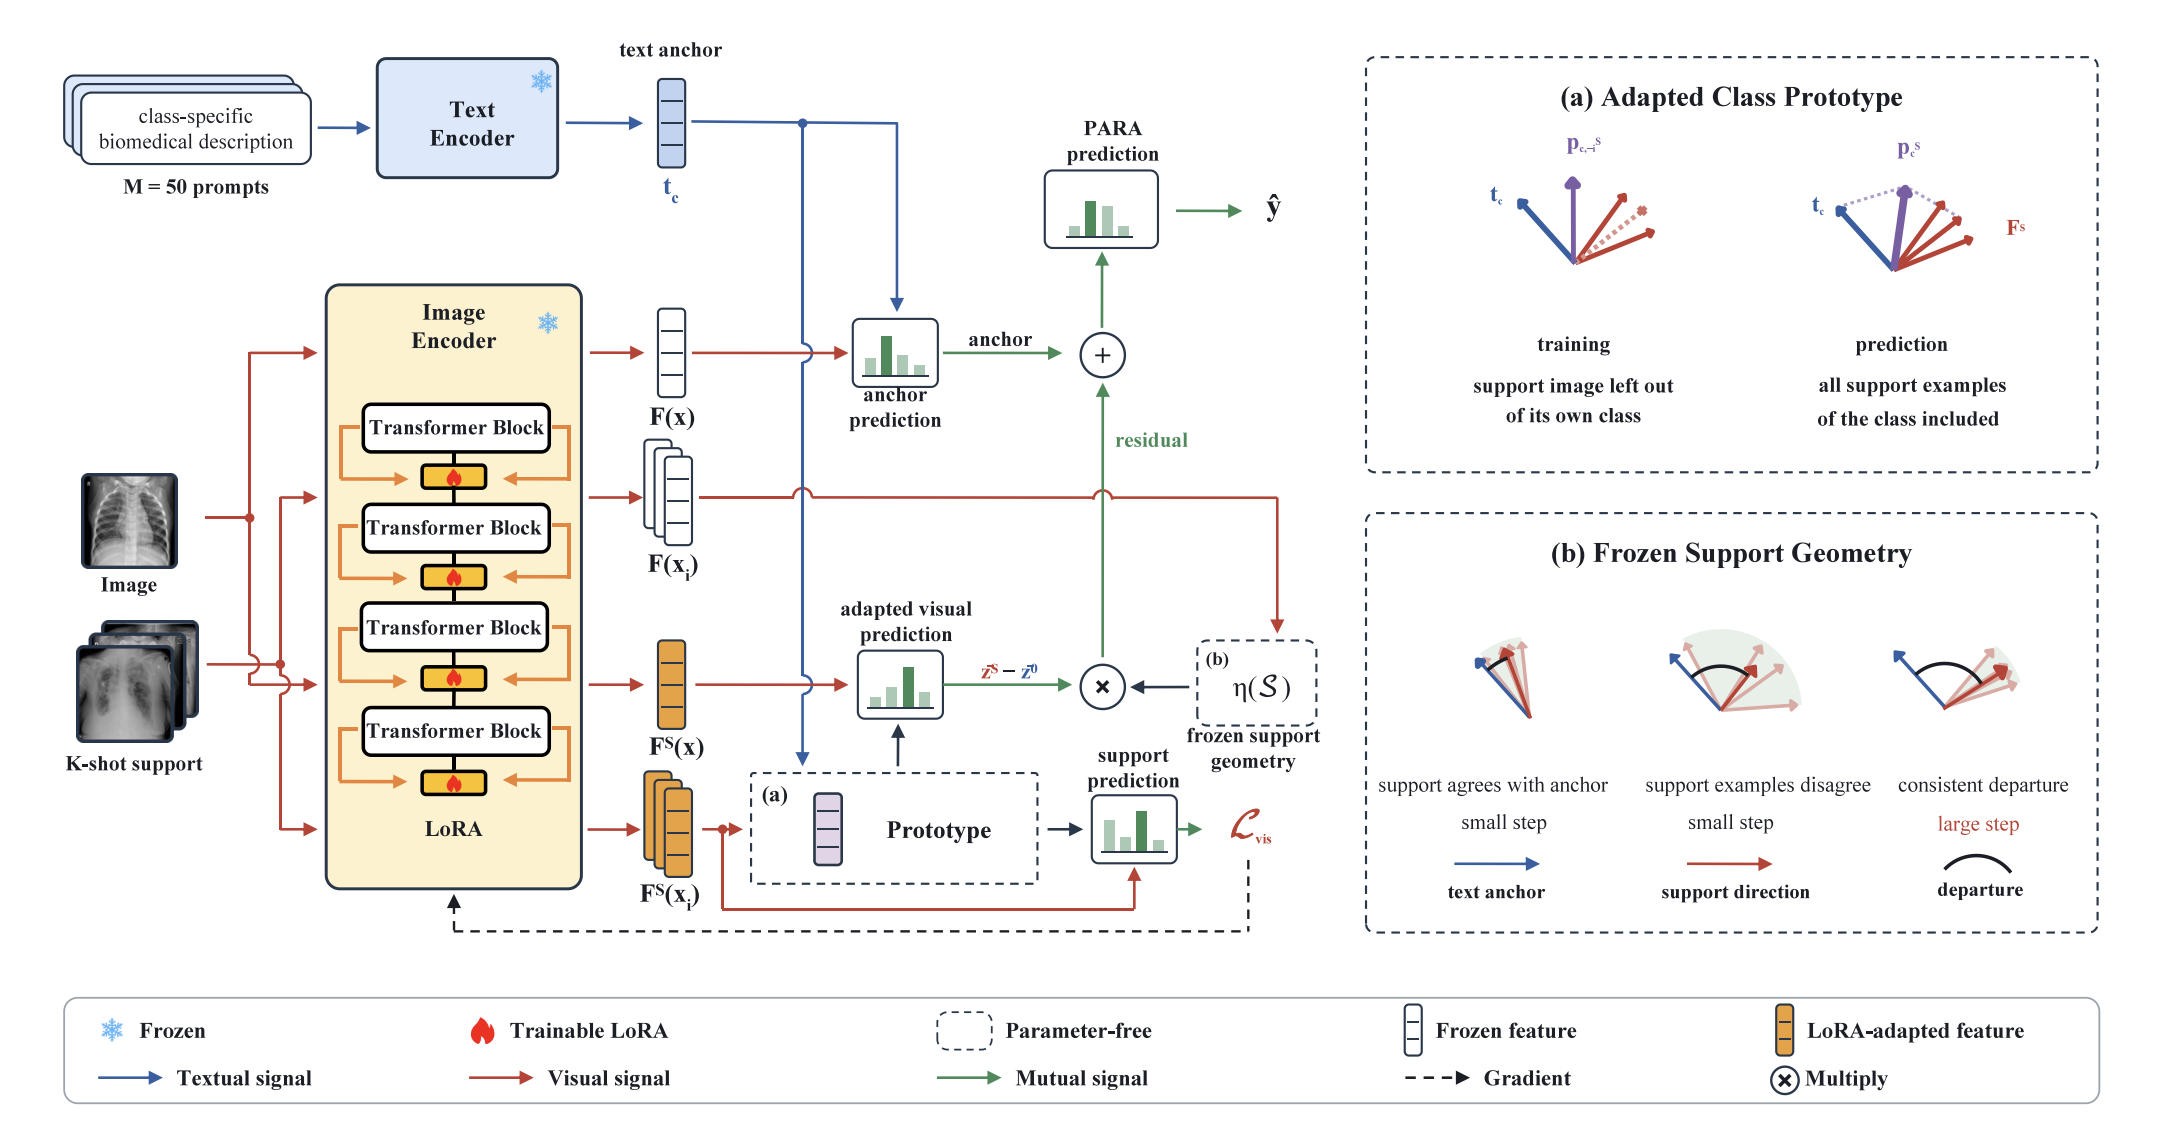

## 1. Setup

- `open_clip_torch` loads **BiomedCLIP** from the Hugging Face hub (the backbone used in the paper).
- `medmnist` gives small, standardised biomedical datasets with one-line download. **DermaMNIST** (skin lesion
  dermoscopy, 7 classes) is one of the paper's 11 datasets, so we use it by default.

In [18]:
!pip -q install open_clip_torch medmnist

In [19]:
import os, math, time, random, contextlib       # standard library helpers
from glob import glob                            # find files by pattern (own-dataset option)

import numpy as np                               # arrays and math on the CPU
import torch                                     # PyTorch, the deep learning library
import torch.nn as nn                            # building blocks for neural networks (layers, Parameter)
import torch.nn.functional as F                  # functions like cross_entropy and normalize
import matplotlib.pyplot as plt                  # plotting
from PIL import Image                            # open / convert images
from torchvision import transforms as Tr         # image augmentations (random crop, flip)
from sklearn.metrics import f1_score             # Macro-F1, the paper's second metric
import open_clip                                 # loads BiomedCLIP and its tokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"   # use the GPU if there is one
USE_AMP = device == "cuda"                       # mixed precision (16-bit) training only makes sense on a GPU
print("Device:", device)

def set_seed(seed):
    # Fix every random number generator so a run can be repeated exactly
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Device: cuda


## 2. Settings

All knobs in one place. Values marked *(paper)* are the ones reported in the paper's implementation details.

In [ ]:
SEED = 1                   # master random seed

DATASET = "octmnist"     # any 2D single-label MedMNIST name ("dermamnist", "octmnist", "pathmnist",
                           # "bloodmnist", "breastmnist", ...) or "folder" for your own images (see section 4)
MEDMNIST_SIZE = 128        # MedMNIST+ image size: 224 matches BiomedCLIP's input; 128 or 64 download faster
DATA_DIR = "/content/my_dataset"   # only used when DATASET = "folder"
N_TEST = 2000              # max test images (random subset) to keep evaluation quick; None = all

SHOTS = 16                 # K: labelled support images per class (paper: K in {1, 2, 4, 8, 16})

LORA_RANK = 8              # rank r of each LoRA update (paper)
LORA_ALPHA = 16            # LoRA scaling alpha; the update is multiplied by alpha / r = 2 (paper)
EPOCHS = 80                # passes over the support set (paper)
BATCH_SIZE = 32            # support images per training step (not specified in the paper)
LR_LORA = 1e-4             # AdamW learning rate for the LoRA weights (paper)
LR_SCALE = 1e-3            # AdamW learning rate for the visual logit scale tau_v (paper)
WEIGHT_DECAY = 1e-4        # AdamW weight decay (paper)

LAMBDA = 0.9               # global upper bound of the residual step eta(S) (paper, same for all datasets)
BETA, GAMMA = 20.0, 0.2    # base-to-novel transport: semantic selectivity beta, transfer size gamma (paper)

set_seed(SEED)             # make everything below repeatable

## 3. Load BiomedCLIP and freeze it

BiomedCLIP = a ViT-B/16 image encoder + a PubMedBERT text encoder, both mapping into a shared 512-number space.

- **Freezing:** `requires_grad_(False)` means PyTorch will never change these weights. The only trainable things
  will be the LoRA adapters we insert later, plus one number (`tau_v`).
- **`tau0` (logit scale):** a learned "temperature" (about 100 for CLIP). Cosine similarities live in [-1, 1];
  multiplying by tau0 spreads them out so the softmax is sharp. The paper calls it the *frozen pretrained logit scale*.
- We keep the whole model in `eval()` mode all the time: ViT has no batch-norm, and BiomedCLIP's dropout is 0,
  so train/eval mode makes no difference for it.

In [21]:
MODEL_ID = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"   # official BiomedCLIP checkpoint
model, preprocess = open_clip.create_model_from_pretrained(MODEL_ID)   # model + deterministic image preprocessing
tokenizer = open_clip.get_tokenizer(MODEL_ID)    # turns sentences into token IDs for PubMedBERT
model = model.to(device).eval()                  # move to GPU, evaluation mode
for p in model.parameters():                     # loop over every pretrained weight tensor
    p.requires_grad_(False)                      # freeze it

tau0 = model.logit_scale.exp().item()            # frozen logit scale; stored as a log value, so exp() it
print(f"tau0 = {tau0:.2f}")
print(preprocess)                                # resize to 224, centre crop, convert to tensor, normalise

tau0 = 85.23
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)


## 4. Data: a support pool and a fixed test set

The paper splits every dataset once into a **support pool** (30%, where few-shot examples are drawn from) and a
fixed **test set** (70%). MedMNIST already comes with official splits, so we use its `train` split as the support
pool and its `test` split as the test set. They never overlap, which is what matters.

What this cell builds:
- `classnames`: list of class names
- `pool_labels`, `get_pool(i)`: labels of the support pool, and a function returning pool image `i` as a PIL image
- `test_idx`, `y_test`, `get_test(i)`: same for the test set

**Your own data (`DATASET = "folder"`):** one sub-folder per class, e.g. `my_dataset/benign/*.png`.
Each class is split 30 / 70 into pool / test like in the paper.

In [22]:
if DATASET != "folder":
    import medmnist                                          # the MedMNIST package
    from medmnist import INFO                                # metadata: class names, task type, ...
    info = INFO[DATASET]                                     # info for the chosen dataset
    assert info["task"].startswith("multi-class") or info["task"] == "binary-class", "need a single-label dataset"
    DataClass = getattr(medmnist, info["python_class"])      # e.g. medmnist.DermaMNIST
    root = "/content/medmnist" if os.path.isdir("/content") else "./medmnist"   # where the .npz file goes
    os.makedirs(root, exist_ok=True)                         # create the folder if it doesn't exist
    pool_ds = DataClass(split="train", download=True, size=MEDMNIST_SIZE, root=root)   # support pool
    test_ds = DataClass(split="test", download=True, size=MEDMNIST_SIZE, root=root)    # test set
    classnames = [info["label"][str(i)] for i in range(len(info["label"]))]   # "0" -> "actinic keratoses ..."
    pool_labels = pool_ds.labels.flatten().astype(np.int64)  # stored as uint8 [N, 1]; flatten to [N], int64 for PyTorch
    test_labels_all = test_ds.labels.flatten().astype(np.int64)
    # "getter" functions: index -> PIL image. MedMNIST stores raw pixels; .convert("RGB") makes grayscale 3-channel
    get_pool = lambda i: Image.fromarray(pool_ds.imgs[i]).convert("RGB")
    get_test = lambda i: Image.fromarray(test_ds.imgs[i]).convert("RGB")

else:
    EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")   # accepted image file types
    class_dirs = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
    classnames = [d.replace("_", " ") for d in class_dirs]   # folder "benign_tumor" -> class "benign tumor"
    rng_split = np.random.default_rng(SEED)                  # seeded RNG so the split is the same every run
    pool_paths, pool_y, test_paths, test_y = [], [], [], []
    for ci, d in enumerate(class_dirs):                      # ci = class number
        ps = sorted(p for p in glob(os.path.join(DATA_DIR, d, "*")) if p.lower().endswith(EXTS))
        ps = list(rng_split.permutation(ps))                 # shuffle this class's files
        cut = int(round(0.3 * len(ps)))                      # 30% support pool, 70% test (paper)
        pool_paths += ps[:cut]; pool_y += [ci] * cut
        test_paths += ps[cut:]; test_y += [ci] * (len(ps) - cut)
    pool_labels, test_labels_all = np.array(pool_y), np.array(test_y)
    get_pool = lambda i: Image.open(pool_paths[i]).convert("RGB")
    get_test = lambda i: Image.open(test_paths[i]).convert("RGB")

C = len(classnames)                                          # number of classes
rng = np.random.default_rng(SEED)                            # RNG for the test subset
test_idx = np.arange(len(test_labels_all))                   # all test indices
if N_TEST is not None and len(test_idx) > N_TEST:
    test_idx = np.sort(rng.choice(test_idx, N_TEST, replace=False))   # random subset, sorted for tidiness
y_test = test_labels_all[test_idx]                           # labels of the test images we use
y_test_t = torch.tensor(y_test, device=device)               # same, as a GPU tensor

print(f"{C} classes:", classnames)
print("support pool per class:", np.bincount(pool_labels, minlength=C))
print("test images per class :", np.bincount(y_test, minlength=C))

2 classes: ['malignant', 'normal, benign']
support pool per class: [147 399]
test images per class : [ 42 114]


### Drawing a support set

A **support draw** = exactly `K` random pool images per class. The paper evaluates many draws (20) and gives every
method the *same* draws. Here a draw is identified by an integer seed, so draw `3` is always the same images.

*(The paper also balances how often each pool image is reused across draws. We just draw independently.)*

support set size: 32 | labels: [16 16]


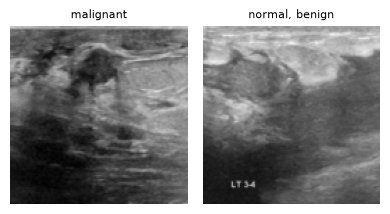

In [23]:
def draw_support(k, draw_seed, classes=None):
    # Returns pool indices of k images per class (classes = all classes unless a subset is given)
    rng_d = np.random.default_rng(1000 + draw_seed)          # one fixed RNG per draw
    classes = range(C) if classes is None else classes
    idx = []
    for c in classes:
        cand = np.where(pool_labels == c)[0]                 # pool images of class c
        idx += list(rng_d.choice(cand, size=min(k, len(cand)), replace=False))   # k of them, no repeats
    return np.array(idx)

sup_idx = draw_support(SHOTS, draw_seed=0)                   # the draw we use for sections 8-10
print("support set size:", len(sup_idx), "| labels:", np.bincount(pool_labels[sup_idx], minlength=C))

# Look at one support image per class
fig, ax = plt.subplots(1, C, figsize=(2 * C, 2.4))
for c in range(C):
    i = sup_idx[pool_labels[sup_idx] == c][0]               # first support image of class c
    ax[c].imshow(get_pool(i)); ax[c].set_title(classnames[c][:18], fontsize=8); ax[c].axis("off")
plt.tight_layout(); plt.show()

## 5. Text anchors (Eq. 1)

Each class `c` gets a **prompt ensemble** of M sentences. Its **text anchor** is

$$t_c = \frac{\sum_m F_t(p_m(c))}{\lVert \sum_m F_t(p_m(c)) \rVert}$$

i.e. embed every sentence, normalise each to length 1, average, and normalise again. Averaging many phrasings
gives a more robust class direction than any single sentence.

The paper uses the **50 GPT-4 descriptions per class released with BiomedCoOp** ("Give N textual descriptions of
visual discriminative features for ... found in [MODALITY]"). We include 5 hand-written descriptions per class for
DermaMNIST in the same spirit. For other datasets we fall back to generic templates. To reproduce the paper exactly,
replace `DESCRIPTIONS` with BiomedCoOp's JSON files.

In [24]:
MODALITY = {"dermamnist": "dermoscopy", "octmnist": "optical coherence tomography", "pathmnist": "histopathology",
            "bloodmnist": "blood cell microscopy", "breastmnist": "breast ultrasound", "pneumoniamnist": "chest X-ray",
            "retinamnist": "fundus photography", "organamnist": "abdominal CT", "tissuemnist": "kidney histology",
            }.get(DATASET, "medical")                      # imaging modality, used inside the prompts

# Visual descriptions per class (DermaMNIST). Keys must match the class names exactly.
DESCRIPTIONS = {
    "actinic keratoses and intraepithelial carcinoma": [
        "a rough scaly patch with a red strawberry pattern around hair follicles",
        "white to yellow surface scale over a pink background",
        "rosettes and target-like follicular openings",
        "fine wavy vessels on a pink-red lesion",
        "a flat or slightly raised lesion on sun-damaged skin"],
    "basal cell carcinoma": [
        "arborizing tree-like branching vessels",
        "blue-gray ovoid nests and globules",
        "leaf-like pigmented areas at the periphery",
        "shiny white-red structureless areas",
        "ulceration without a pigment network"],
    "benign keratosis-like lesions": [
        "milia-like cysts and comedo-like openings",
        "a cerebriform brain-like surface pattern",
        "a sharply demarcated waxy stuck-on appearance",
        "fingerprint-like light brown structures",
        "moth-eaten borders"],
    "dermatofibroma": [
        "a central white scar-like patch",
        "a delicate light brown pigment network at the periphery",
        "a small firm brown nodule",
        "ring-like globules around a white center",
        "a symmetric lesion with a light center and darker rim"],
    "melanoma": [
        "an asymmetric lesion with irregular borders",
        "multiple colors including black, brown, blue and red",
        "an atypical pigment network with thick irregular lines",
        "a blue-white veil",
        "irregular dots, globules and streaks at the periphery"],
    "melanocytic nevi": [
        "a symmetric lesion with a regular pigment network",
        "a uniform brown color",
        "a smooth regular border",
        "evenly distributed dots and globules",
        "a small round homogeneous lesion"],
    "vascular lesions": [
        "red, purple or blue lacunae",
        "well-demarcated red-blue lobules",
        "whitish fibrous septa separating red areas",
        "no pigment network",
        "a homogeneous bright red to dark purple color"],
}

TEMPLATES = ["a {m} image of {c}.", "a {m} image showing {c}.", "{c} as seen in {m}.",
             "an example of {c} in a {m} image.", "a medical image of {c}."]   # fallback prompts

def class_prompts(name):
    # Build the prompt ensemble {p_m(c)} for one class
    if name in DESCRIPTIONS:                                # descriptive prompts when available
        return [f"a {MODALITY} image of {name}, showing {d}." for d in DESCRIPTIONS[name]]
    return [t.format(m=MODALITY, c=name) for t in TEMPLATES]   # otherwise generic templates

@torch.no_grad()                                            # text encoder is frozen: no gradients
def text_anchor(prompts):
    tok = tokenizer(prompts, context_length=256).to(device)  # [M, 256] token IDs (PubMedBERT max length 256)
    e = F.normalize(model.encode_text(tok).float(), dim=-1)  # [M, 512], each sentence embedding has length 1
    return F.normalize(e.mean(0), dim=-1)                   # average, then normalise again (Eq. 1) -> [512]

T_anchor = torch.stack([text_anchor(class_prompts(c)) for c in classnames])   # [C, 512]: one t_c per class
print("text anchors:", tuple(T_anchor.shape))
print("example prompt:", class_prompts(classnames[0])[0])

text anchors: (2, 512)
example prompt: a breast ultrasound image of malignant.


## 6. The anchor branch: zero-shot BiomedCLIP (Eq. 8)

$$z^0_c(x) = \tau_0 \langle F^0_v(x), t_c \rangle$$

Frozen image embedding (`F0_v`) dotted with each text anchor. Since both have length 1, the dot product is the cosine
similarity. This prediction **does not depend on the support set at all**, which is why the paper calls it
*support-invariant*.

We encode the test images once now with the frozen encoder and reuse them everywhere (the anchor branch and the
base-to-novel section both need them).

`encode(...)` takes an `adapted` flag: later, when LoRA is inserted, `adapted=False` switches it off temporarily so we
get the original frozen encoder `F0_v`, and `adapted=True` gives the adapted encoder `FS_v`.

In [25]:
lora_modules = []                                    # filled in section 7; empty = encoder is plain BiomedCLIP

@contextlib.contextmanager
def lora_off():
    # Temporarily disable every LoRA adapter -> the image encoder becomes the frozen F0_v again
    for m in lora_modules: m.enabled = False
    try:
        yield
    finally:
        for m in lora_modules: m.enabled = True     # always switch back on, even if an error happened

@torch.no_grad()                                     # encoding only, no training here
def encode(getter, indices, adapted, bs=128):
    # getter(i) -> PIL image; returns [N, 512] unit-length image embeddings
    feats = []
    ctx = contextlib.nullcontext() if adapted else lora_off()   # choose F^S_v (adapted) or F^0_v (frozen)
    with ctx:
        for i in range(0, len(indices), bs):         # batches of 128 images
            x = torch.stack([preprocess(getter(j)) for j in indices[i:i + bs]]).to(device)   # [b, 3, 224, 224]
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):   # 16-bit math on GPU = faster
                f = model.encode_image(x)            # [b, 512]
            feats.append(F.normalize(f.float(), dim=-1))   # back to 32-bit, length 1
    return torch.cat(feats)                          # [N, 512]

def standardize(z):
    # Per-image z-score across classes: (score - mean over classes) / std over classes.
    # Removes the effect of each branch's own logit scale so the two branches can be mixed fairly.
    return (z - z.mean(-1, keepdim=True)) / (z.std(-1, keepdim=True, unbiased=False) + 1e-8)

def metrics(logits, y):
    # Accuracy and Macro-F1 (mean of per-class F1) in %, the paper's two metrics
    pred = logits.argmax(-1).cpu().numpy()          # predicted class = highest score
    y = y.cpu().numpy() if torch.is_tensor(y) else y
    acc = (pred == y).mean() * 100
    f1 = f1_score(y, pred, average="macro", labels=np.unique(y), zero_division=0) * 100
    return acc, f1

t0 = time.time()
f0_test = encode(get_test, test_idx, adapted=False)  # [N_test, 512] frozen test embeddings F0_v(x)
z0_test = tau0 * f0_test @ T_anchor.T                # [N_test, C] anchor scores z0 (Eq. 8)
print(f"encoded {len(test_idx)} test images in {time.time() - t0:.1f}s")
acc, f1 = metrics(z0_test, y_test)
print(f"Zero-shot BiomedCLIP (anchor branch) | Acc {acc:.2f} | Macro-F1 {f1:.2f}")

encoded 156 test images in 0.7s
Zero-shot BiomedCLIP (anchor branch) | Acc 33.33 | Macro-F1 30.77


## 7. LoRA: a small trainable update inside the image encoder

**LoRA (Low-Rank Adaptation)** leaves a frozen weight matrix `W` untouched and learns a small correction:

$$y = Wx + b + \frac{\alpha}{r} B A x, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$$

With rank r = 8 and d = 768, `A` and `B` have 2 x 8 x 768 = 12k numbers, versus 590k in `W`.
`B` starts at **zero**, so at the start the adapted encoder is *exactly* the frozen one.

The paper puts LoRA on the **query, key, value and output projections** of every attention layer (12 layers).
In timm's ViT, q, k, v are computed by one fused layer `qkv` (768 -> 3 x 768), so we give that layer **three**
separate (A, B) pairs, one per q / k / v slice. This is the same as having separate LoRA on q, k and v.

Also trained: `tau_v`, the **visual logit scale** (one number), created in section 8.

In [26]:
class LoRALinear(nn.Module):
    # Wraps a frozen nn.Linear and adds (alpha / r) * B A x.
    # n_chunks > 1 splits the output into equal slices with their own (A, B), e.g. 3 for fused q|k|v.
    def __init__(self, base, r, alpha, n_chunks=1):
        super().__init__()                                   # required first line for nn.Module subclasses
        self.base = base                                     # the original frozen layer
        self.scale = alpha / r                               # LoRA scaling factor (16 / 8 = 2)
        dev = base.weight.device                             # create new weights on the same device
        out_chunk = base.out_features // n_chunks            # output size of each slice (768 for q, k or v)
        self.A = nn.ParameterList([nn.Parameter(torch.empty(r, base.in_features, device=dev)) for _ in range(n_chunks)])
        self.B = nn.ParameterList([nn.Parameter(torch.empty(out_chunk, r, device=dev)) for _ in range(n_chunks)])
        self.enabled = True                                  # lora_off() flips this to False
        self.reset()                                         # initialise A and B

    def reset(self):
        # Fresh start: A random (standard LoRA init), B zero -> the update B A x is exactly 0
        for A in self.A: nn.init.kaiming_uniform_(A, a=math.sqrt(5))
        for B in self.B: nn.init.zeros_(B)

    def forward(self, x):
        y = self.base(x)                                     # frozen W x + b
        if not self.enabled:                                 # adapters switched off -> frozen encoder
            return y
        # x @ A^T -> [.., r], then @ B^T -> [.., out_chunk]; concatenate the slices -> [.., out_features]
        delta = torch.cat([F.linear(F.linear(x, A.to(x.dtype)), B.to(x.dtype)) for A, B in zip(self.A, self.B)], dim=-1)
        return y + self.scale * delta                        # frozen output + low-rank correction

# Insert LoRA into every attention layer of the ViT image encoder
for blk in model.visual.trunk.blocks:                        # 12 transformer blocks
    attn = blk.attn                                          # the self-attention module of this block
    attn.qkv = LoRALinear(attn.qkv, LORA_RANK, LORA_ALPHA, n_chunks=3)   # q, k, v projections
    attn.proj = LoRALinear(attn.proj, LORA_RANK, LORA_ALPHA)             # output projection
    lora_modules += [attn.qkv, attn.proj]                    # remember them (for lora_off and reset)

lora_params = [p for m in lora_modules for p in list(m.A) + list(m.B)]   # every trainable LoRA tensor
print(f"LoRA modules: {len(lora_modules)} | trainable numbers: {sum(p.numel() for p in lora_params):,}"
      f" | frozen BiomedCLIP image encoder: {sum(p.numel() for p in model.visual.parameters() if not p.requires_grad):,}")

# Sanity check: B = 0, so the adapted encoder must equal the frozen one right now
chk = encode(get_test, test_idx[:4], adapted=True)
print("max |adapted - frozen| at init:", (chk - f0_test[:4]).abs().max().item())   # ~0 (tiny fp16 noise)

LoRA modules: 24 | trainable numbers: 589,824 | frozen BiomedCLIP image encoder: 86,191,872
max |adapted - frozen| at init: 0.0001720339059829712


## 8. Training the visual branch: leave-one-out prototypes (Eq. 2-3)

**Class prototype (Eq. 2):** text anchor + adapted embeddings of that class's support images, normalised:

$$p^S_c = \frac{t_c + \sum_{i \in S_c} F^S_v(x_i)}{\lVert t_c + \sum_{i \in S_c} F^S_v(x_i) \rVert}$$

Because `t_c` is in the sum, the prototype is **anchored** to the text: with few images it stays close to the text,
with many images the images dominate.

**Why leave-one-out?** If image `x_i` is part of its own class prototype, the easy way to lower the loss is to make
`x_i` similar to *itself*, not to its class. So when classifying training image `i`, its own embedding is removed
from its own class prototype (other classes' prototypes stay as they are):

$$\mathcal{L}_{vis} = \frac{1}{N}\sum_i \mathrm{CE}\Big(\tau_v \big[\langle F^S_v(x_i), p^S_{c,-i}\rangle\big]_{c}, y_i\Big)$$

With 1 shot, the positive prototype is just the text anchor `t_c`, and the image still trains the adapter.

**Implementation detail (Not specified in the paper):** the prototypes need the adapted embedding of *every* support image,
but we only push `BATCH_SIZE` images through the encoder per step. We therefore keep a **feature bank**: the most recent
embedding of each support image. Images in the current batch use their live embedding (gradients flow through
them), and all the others come from the bank (no gradients). The bank starts as the frozen embeddings, which equal the
adapted ones at initialisation because B = 0.

**Training recipe (paper):** 80 epochs, AdamW, lr 1e-4 (LoRA) and 1e-3 (tau_v), weight decay 1e-4, random resized
crops + horizontal flips, final checkpoint (no validation set).

epoch   1/80 | loss 0.7423 | tau_v 85.15
epoch  11/80 | loss 0.6189 | tau_v 84.36
epoch  21/80 | loss 0.2899 | tau_v 83.87
epoch  31/80 | loss 0.2672 | tau_v 83.91
epoch  41/80 | loss 0.1430 | tau_v 84.27
epoch  51/80 | loss 0.0181 | tau_v 84.66
epoch  61/80 | loss 0.0018 | tau_v 84.83
epoch  71/80 | loss 0.0334 | tau_v 84.90
epoch  80/80 | loss 0.1666 | tau_v 84.94
trained in 24s


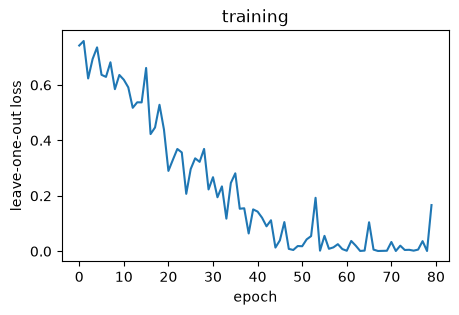

In [27]:
mean_std = [t for t in preprocess.transforms if isinstance(t, Tr.Normalize)][0]   # BiomedCLIP's pixel normalisation
train_tf = Tr.Compose([
    Tr.RandomResizedCrop(224, scale=(0.5, 1.0), interpolation=Tr.InterpolationMode.BICUBIC),  # random zoom + crop
    Tr.RandomHorizontalFlip(),                       # mirror left-right half of the time
    Tr.ToTensor(),                                   # PIL image -> [3, 224, 224] tensor in [0, 1]
    mean_std,                                        # same normalisation as the pretrained model expects
])  # crop scale range is not specified in the paper; (0.5, 1) keeps most of each lesion in view

def train_visual_branch(sup_idx, sup_y, T, seed, epochs=EPOCHS, verbose=True):
    # sup_idx: pool indices of the support set; sup_y: their labels 0..K-1 (local to T); T: [K, 512] text anchors
    # Trains the LoRA weights and tau_v with the leave-one-out loss. Returns tau_v and the loss history.
    set_seed(seed)                                   # optimisation seed (the paper uses 3 per support draw)
    for m in lora_modules: m.reset()                 # start from the frozen encoder every time
    Kc = T.shape[0]                                  # number of classes in this task
    imgs = [get_pool(i) for i in sup_idx]            # keep the support images in memory (PIL)
    y = torch.as_tensor(sup_y, dtype=torch.long, device=device)        # [N] labels
    N = len(imgs)
    onehot = F.one_hot(y, Kc).float()                # [N, Kc]: row i has a 1 at column y_i

    log_tau_v = nn.Parameter(torch.tensor(math.log(tau0), device=device))   # tau_v, starts at tau0 (log for positivity)
    opt = torch.optim.AdamW([{"params": lora_params, "lr": LR_LORA},
                             {"params": [log_tau_v], "lr": LR_SCALE}], weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)   # scales the loss so 16-bit gradients don't underflow

    bank = encode(get_pool, sup_idx, adapted=True).clone()   # [N, 512] feature bank (= frozen features right now)
    history = []
    for epoch in range(epochs):
        perm = torch.randperm(N, device=device)      # new random order of support images every epoch
        tot = 0.0
        for s in range(0, N, BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]               # indices (into the support set) of this batch
            x = torch.stack([train_tf(imgs[j]) for j in b.tolist()]).to(device)   # augmented images [B, 3, 224, 224]
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                f = model.encode_image(x)            # adapted embeddings F^S_v(x_i), gradients flow into LoRA
            f = F.normalize(f.float(), dim=-1)       # [B, 512], unit length

            feats = bank.index_put((b,), f)          # [N, 512]: bank, with this batch's rows replaced by live features
            S = T + onehot.T @ feats                 # [Kc, 512]: t_c + sum of class-c support features (Eq. 2, unnormalised)
            own = F.one_hot(y[b], Kc).float().unsqueeze(-1) * f.unsqueeze(1)   # [B, Kc, 512]: f_i at its own class only
            P = F.normalize(S.unsqueeze(0) - own, dim=-1)   # [B, Kc, 512]: leave-one-out prototypes p_{c,-i}
            logits = log_tau_v.exp() * torch.einsum("bd,bcd->bc", f, P)   # [B, Kc]: tau_v * <f_i, p_{c,-i}>
            loss = F.cross_entropy(logits, y[b])     # Eq. 3

            opt.zero_grad(set_to_none=True)          # clear old gradients
            scaler.scale(loss).backward()            # backward pass: gradients for LoRA and tau_v
            scaler.step(opt)                         # AdamW update
            scaler.update()                          # adjust the loss scale for next step
            bank[b] = f.detach()                     # refresh the bank with the newest features
            tot += loss.item() * len(b)
        history.append(tot / N)                      # average loss this epoch
        if verbose and (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch + 1:3d}/{epochs} | loss {history[-1]:.4f} | tau_v {log_tau_v.exp().item():.2f}")
    return log_tau_v.exp().item(), history

t0 = time.time()
sup_y = pool_labels[sup_idx]                         # labels of the support draw from section 4
tau_v, hist = train_visual_branch(sup_idx, sup_y, T_anchor, seed=SEED)
print(f"trained in {time.time() - t0:.0f}s")
plt.figure(figsize=(5, 3)); plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("leave-one-out loss"); plt.title("training"); plt.show()

## 9. Inference: visual branch, support geometry, and the PARA prediction

### 9a. Visual branch (Eq. 4)
At test time, prototypes use **all** support images (no leave-one-out) encoded with the adapted encoder and the
deterministic preprocessing (no augmentation):  $z^S_c(x) = \tau_v \langle F^S_v(x), p^S_c \rangle$.

### 9b. Frozen support geometry (Eq. 5-7)
Using the **frozen** support embeddings $u_i = F^0_v(x_i)$ (so it does not depend on training randomness):

- $h_c = \sum_{i \in S_c} u_i$ (the class resultant vector), $d_c = h_c / \lVert h_c \rVert$ (its direction)
- **anchor discrepancy** $\delta_c = 1 - \langle d_c, t_c \rangle \in [0, 2]$: 0 if the images point exactly where the text points
- **support agreement** $\phi_c = \lVert h_c \rVert^2 / n_c \in [0, n_c]$: unit vectors that agree add up
  (|h| = n, phi = n), vectors that disagree cancel (phi small). Equals 1 with one shot.

### 9c. Residual step (Eq. 10)
$$\eta(S) = \frac{\lambda}{C} \sum_c \frac{\delta_c \phi_c}{1 + \delta_c \phi_c} \in [0, \lambda)$$
The product delta x phi is a soft "AND", a / (1 + a) squashes each class's vote into [0, 1), and averaging over
classes makes it comparable across datasets.

### 9d. Final prediction (Eq. 9)
Standardise each branch's scores across classes, then move from the anchor towards the visual branch by eta:
$$\hat z_c(x) = \bar z^0_c(x) + \eta(S)\,\big(\bar z^S_c(x) - \bar z^0_c(x)\big), \qquad \hat y = \arg\max_c \hat z_c(x)$$

In [28]:
@torch.no_grad()
def visual_branch_logits(sup_idx, sup_y, T, tau_v, f_test_adapted):
    # Eq. 2 with all support images + Eq. 4
    Kc = T.shape[0]
    fs = encode(get_pool, sup_idx, adapted=True)              # [N, 512] adapted support embeddings, no augmentation
    onehot = F.one_hot(torch.as_tensor(sup_y, dtype=torch.long, device=device), Kc).float()   # [N, Kc]
    protos = F.normalize(T + onehot.T @ fs, dim=-1)           # [Kc, 512] prototypes p^S_c
    return tau_v * f_test_adapted @ protos.T                  # [N_test, Kc] visual scores z^S

@torch.no_grad()
def support_geometry(sup_idx, sup_y, T, lam=LAMBDA):
    # Eq. 5-7 and 10, computed from FROZEN support embeddings u_i
    Kc = T.shape[0]
    u = encode(get_pool, sup_idx, adapted=False)              # [N, 512] u_i = F0_v(x_i)
    onehot = F.one_hot(torch.as_tensor(sup_y, dtype=torch.long, device=device), Kc).float()
    h = onehot.T @ u                                          # [Kc, 512] h_c = sum of class-c support vectors
    n = onehot.sum(0)                                         # [Kc] n_c = number of support images per class
    d = F.normalize(h, dim=-1)                                # [Kc, 512] visual direction d_c
    delta = 1 - (d * T).sum(-1)                               # [Kc] anchor discrepancy, 1 - cos(d_c, t_c)
    phi = h.norm(dim=-1) ** 2 / n                             # [Kc] support agreement ||h_c||^2 / n_c
    a = delta * phi                                           # [Kc] soft conjunction
    eta = lam * (a / (1 + a)).mean().item()                   # Eq. 10: bounded, averaged over classes
    return eta, delta, phi, d

def para_logits(z0, zS, eta):
    # Eq. 9: anchor + eta * (visual - anchor), both standardised across classes
    z0b, zSb = standardize(z0), standardize(zS)
    return z0b + eta * (zSb - z0b)

fS_test = encode(get_test, test_idx, adapted=True)            # [N_test, 512] adapted test embeddings F^S_v(x)
zS_test = visual_branch_logits(sup_idx, sup_y, T_anchor, tau_v, fS_test)   # visual branch scores
eta, delta, phi, _ = support_geometry(sup_idx, sup_y, T_anchor)            # residual step from frozen geometry
zP_test = para_logits(z0_test, zS_test, eta)                 # final PARA scores

print(f"{'class':<48} {'delta':>7} {'phi':>7} {'delta*phi':>10}")
for c in range(C):
    print(f"{classnames[c][:48]:<48} {delta[c]:7.3f} {phi[c]:7.2f} {(delta[c] * phi[c]):10.3f}")
print(f"\neta(S) = {eta:.3f}   (upper bound lambda = {LAMBDA})")

class                                              delta     phi  delta*phi
malignant                                          0.512   14.04      7.183
normal, benign                                     0.569   13.43      7.646

eta(S) = 0.793   (upper bound lambda = 0.9)


## 10. Results and free ablations

Because PARA only mixes two sets of scores, two of the paper's ablations (Table 4) cost nothing to compute:
- **w/o prompt-anchored residual**: use the visual branch alone (eta = 1)
- **w/o support geometry**: fixed step eta = 0.5 instead of eta(S)

(The third ablation, *w/o prototype anchoring*, drops `t_c` from Eq. 2 and needs retraining, so we skip it.)

Expect PARA to be at least as good as both branches on average. When the text anchor is weak and the visual branch is
strong (the paper's CHMNIST failure case), PARA can land between them.

Zero-shot (anchor)     | Acc  31.90 | Macro-F1  15.64
Visual branch only     | Acc  56.45 | Macro-F1  41.98
Fixed eta = 0.5        | Acc  52.80 | Macro-F1  37.28
PARA (eta = 0.79)      | Acc  57.40 | Macro-F1  43.15


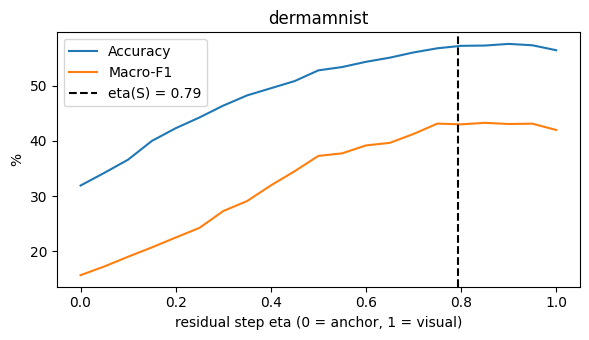

In [12]:
results = {
    "Zero-shot (anchor)":     metrics(z0_test, y_test),                         # eta = 0
    "Visual branch only":     metrics(zS_test, y_test),                         # eta = 1
    "Fixed eta = 0.5":        metrics(para_logits(z0_test, zS_test, 0.5), y_test),
    f"PARA (eta = {eta:.2f})": metrics(zP_test, y_test),
}
for k, (a, f) in results.items():
    print(f"{k:<22} | Acc {a:6.2f} | Macro-F1 {f:6.2f}")

# Sweep eta from 0 to 1 to see where eta(S) lands on the curve
etas = np.linspace(0, 1, 21)
sweep = np.array([metrics(para_logits(z0_test, zS_test, e), y_test) for e in etas])   # [21, 2]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(etas, sweep[:, 0], label="Accuracy"); ax.plot(etas, sweep[:, 1], label="Macro-F1")
ax.axvline(eta, color="k", ls="--", label=f"eta(S) = {eta:.2f}")   # the step PARA picked, without any labels
ax.set_xlabel("residual step eta (0 = anchor, 1 = visual)"); ax.set_ylabel("%"); ax.legend(); ax.set_title(DATASET)
plt.tight_layout(); plt.show()

## 11. (Optional) Repeated-support protocol: mean and CVaR20

The paper's second contribution is *how to evaluate*. One support draw tells you little, because a different draw can
give a very different score. Their protocol:

1. Draw **D = 20** support sets per dataset and shot level, shared by all methods.
2. For each draw, run **3 optimisation seeds** and average them. This removes optimiser noise, so the remaining
   spread comes from *which images were drawn*.
3. Report the **mean** over draws, and **CVaR20** = average of the worst 20% of draws (the 4 lowest of 20).
   CVaR20 answers "how bad is it if I'm unlucky with my labelled examples?"

Full scale (20 draws x 3 seeds x 5 shot levels) is far too slow for Colab, so the defaults below are small.
CVaR20 then averages the worst `ceil(0.2 * D)` draws.

In [13]:
RUN_PROTOCOL = True        # set False to skip this section
N_DRAWS = 5                # paper: 20
N_OPT_SEEDS = 1            # paper: 3
PROTOCOL_SHOTS = [SHOTS]   # paper: [1, 2, 4, 8, 16]

def cvar20(values):
    # mean of the worst 20% of support draws (at least one)
    v = np.sort(np.asarray(values))                         # ascending: worst first
    return v[:max(1, math.ceil(0.2 * len(v)))].mean()

if RUN_PROTOCOL:
    methods = ["Zero-shot", "Visual only", "Fixed eta 0.5", "PARA"]
    table = {}                                               # (shots, method) -> list of per-draw (acc, f1)
    for k in PROTOCOL_SHOTS:
        for d in range(N_DRAWS):
            s_idx = draw_support(k, draw_seed=d)             # same draw d for every method
            s_y = pool_labels[s_idx]
            eta_d = support_geometry(s_idx, s_y, T_anchor)[0]   # eta depends only on the draw, not the seed
            per_seed = {m: [] for m in methods}
            for s in range(N_OPT_SEEDS):
                tv, _ = train_visual_branch(s_idx, s_y, T_anchor, seed=s, verbose=False)
                zS = visual_branch_logits(s_idx, s_y, T_anchor, tv, encode(get_test, test_idx, adapted=True))
                per_seed["Zero-shot"].append(metrics(z0_test, y_test))
                per_seed["Visual only"].append(metrics(zS, y_test))
                per_seed["Fixed eta 0.5"].append(metrics(para_logits(z0_test, zS, 0.5), y_test))
                per_seed["PARA"].append(metrics(para_logits(z0_test, zS, eta_d), y_test))
            for m in methods:                                # Eq. A1: average the seeds within this draw
                table.setdefault((k, m), []).append(np.mean(per_seed[m], axis=0))
            print(f"K={k} draw {d + 1}/{N_DRAWS} | eta {eta_d:.3f} | PARA Acc {table[(k, 'PARA')][-1][0]:.2f}")

    print(f"\n{'K':>3} {'method':<14} {'Acc mean':>9} {'Acc SD':>7} {'Acc CVaR20':>11} {'F1 mean':>8} {'F1 CVaR20':>10}")
    for (k, m), vals in table.items():
        v = np.array(vals)                                   # [D, 2] per-draw (acc, f1)
        print(f"{k:>3} {m:<14} {v[:, 0].mean():9.2f} {v[:, 0].std():7.2f} {cvar20(v[:, 0]):11.2f}"
              f" {v[:, 1].mean():8.2f} {cvar20(v[:, 1]):10.2f}")    # SD = population SD over draws (Eq. A2)

K=16 draw 1/5 | eta 0.794 | PARA Acc 56.05
K=16 draw 2/5 | eta 0.793 | PARA Acc 54.70
K=16 draw 3/5 | eta 0.791 | PARA Acc 60.15
K=16 draw 4/5 | eta 0.793 | PARA Acc 59.30
K=16 draw 5/5 | eta 0.793 | PARA Acc 59.80

  K method          Acc mean  Acc SD  Acc CVaR20  F1 mean  F1 CVaR20
 16 Zero-shot          31.90    0.00       31.90    15.64      15.64
 16 Visual only        58.27    2.68       54.55    43.92      41.68
 16 Fixed eta 0.5      51.82    1.09       50.40    37.04      35.03
 16 PARA               58.00    2.20       54.70    44.75      42.32


## 12. Base-to-novel: residual transport (Eq. 11-14)

Split the classes into **base** (with 16-shot support) and **novel** (no labelled images at all). Base test images
are classified among base classes and novel test images among novel classes (the standard protocol).

- **Base classes:** ordinary PARA trained on base support only.
- **Novel classes:** no support -> no visual branch, no `d_n`. Instead, borrow how image directions differ from text
  directions on base classes:
  1. Displacement for each base class: $\Delta_b = d_b - t_b$ (Eq. 11), in the frozen space.
  2. Weights from text similarity: $w_{nb} = \mathrm{softmax}_b(\beta \langle t_n, t_b \rangle)$ (Eq. 12). Higher beta =
     only the most similar base classes count.
  3. Shifted anchor: $t'_n = \mathrm{normalize}(t_n + \gamma \sum_b w_{nb} \Delta_b)$ (Eq. 13), gamma = transfer size.
  4. Score with the frozen encoder: $z'_n(x) = \tau_0 \langle F^0_v(x), t'_n \rangle$ (Eq. 14).

Intuition: if images of "melanoma" sit in a different direction than the word embeddings suggest, a similar novel class
probably has a similar text-image gap, so we nudge its anchor the same way.

We use the first half of the classes as base (the paper uses BiomedCoOp's splits).

In [14]:
n_base = math.ceil(C / 2)                                     # e.g. 4 of 7 classes
base_cls, novel_cls = list(range(n_base)), list(range(n_base, C))
print("base :", [classnames[c] for c in base_cls])
print("novel:", [classnames[c] for c in novel_cls])
T_base, T_novel = T_anchor[base_cls], T_anchor[novel_cls]     # [B, 512], [Nn, 512] text anchors

# --- Base classes: PARA trained on base support only ---
b_idx = draw_support(16, draw_seed=0, classes=base_cls)       # 16-shot support from base classes only
b_y = pool_labels[b_idx]                                      # global labels 0..n_base-1 (base classes come first)
tv_b, _ = train_visual_branch(b_idx, b_y, T_base, seed=SEED, verbose=False)
eta_b, _, _, d_base = support_geometry(b_idx, b_y, T_base)    # eta and base visual directions d_b (frozen space)

mb = np.isin(y_test, base_cls)                                # test images whose true class is a base class
yb = y_test[mb]                                               # their labels (already 0..n_base-1)
z0_b = tau0 * f0_test[mb] @ T_base.T                          # anchor scores among base classes
zS_b = visual_branch_logits(b_idx, b_y, T_base, tv_b, encode(get_test, test_idx[mb], adapted=True))
base_zs, base_para = metrics(z0_b, yb), metrics(para_logits(z0_b, zS_b, eta_b), yb)

# --- Novel classes: residual transport ---
Delta = d_base - T_base                                       # [B, 512] Eq. 11: visual - text displacement
w = torch.softmax(BETA * T_novel @ T_base.T, dim=-1)          # [Nn, B]  Eq. 12: semantic transfer weights
T_novel_new = F.normalize(T_novel + GAMMA * w @ Delta, dim=-1)   # [Nn, 512] Eq. 13: shifted novel anchors

mn = np.isin(y_test, novel_cls)                               # test images of novel classes
yn = y_test[mn] - n_base                                      # relabel to 0..Nn-1
novel_zs = metrics(tau0 * f0_test[mn] @ T_novel.T, yn)        # zero-shot novel
novel_para = metrics(tau0 * f0_test[mn] @ T_novel_new.T, yn)  # Eq. 14: transported anchors, frozen encoder

hm = lambda b, n: 2 * b * n / (b + n)                         # harmonic mean of base and novel
print(f"eta(base support) = {eta_b:.3f}")
print("transfer weights w_nb (rows: novel, cols: base):\n", np.round(w.cpu().numpy(), 2))
print(f"\n{'':<12} {'Base Acc':>9} {'Novel Acc':>10} {'HM':>7} | {'Base F1':>8} {'Novel F1':>9} {'HM':>7}")
for name, b, n in [("Zero-shot", base_zs, novel_zs), ("PARA", base_para, novel_para)]:
    print(f"{name:<12} {b[0]:9.2f} {n[0]:10.2f} {hm(b[0], n[0]):7.2f} | {b[1]:8.2f} {n[1]:9.2f} {hm(b[1], n[1]):7.2f}")

base : ['actinic keratoses and intraepithelial carcinoma', 'basal cell carcinoma', 'benign keratosis-like lesions', 'dermatofibroma']
novel: ['melanoma', 'melanocytic nevi', 'vascular lesions']
eta(base support) = 0.794
transfer weights w_nb (rows: novel, cols: base):
 [[0.08 0.45 0.2  0.27]
 [0.04 0.37 0.18 0.41]
 [0.15 0.33 0.32 0.21]]

              Base Acc  Novel Acc      HM |  Base F1  Novel F1      HM
Zero-shot        22.33      56.55   32.02 |    17.13     37.39   23.50
PARA             64.56      46.85   54.30 |    55.05     34.19   42.18


## 13. Things to try

- `SHOTS = 1` vs `16`: watch eta(S) grow with K (phi grows with agreeing examples), and the gap between PARA and the
  visual branch change.
- Another dataset (`DATASET = "octmnist"`, `"pathmnist"`, `"bloodmnist"`): on datasets where zero-shot is very weak,
  the visual branch can beat PARA (the paper's CHMNIST failure analysis).
- `LAMBDA`: the paper fixes 0.9 everywhere with no tuning; the eta-sweep plot in section 10 shows how much is lost or
  gained by that choice on your data.
- Raise `N_DRAWS` in section 11 and compare the **CVaR20** of "Visual only" against PARA: the paper's main claim is that
  anchoring helps the worst draws most.


## 14. Follow-up experiments (v2)

| Part | Question | Training? | Time on T4 |
|---|---|---|---|
| 14.2 | **Do delta and phi measure what the paper says?** Is delta class-specific? Do random mixed images look as "agreeing" as a real class? | No | ~1 min |
| 14.3 | **Zero-shot with BiomedCoOp's 50 GPT-4 descriptions** vs your own prompts, incl. **balanced accuracy** and per-class predictions | No | ~1 min |
| 14.4 | **Shot sweep K = 1, 4, 16 over 10 draws**, for both prompt sets | Yes | ~20-25 min per prompt set (DermaMNIST) |
| 14.5 | **Which eta rule works?** PARA's eta(S), shot-only, centered, and the new **reliability-based eta**, against three oracles (best eta by Accuracy, by Macro-F1, by balanced accuracy) | No (cached) | seconds |
| 14.6 | **Your own eta rule**, scored on the cached runs | No (cached) | seconds |

**What changed from v1**
- **Balanced accuracy (BAcc)** everywhere: the average of per-class recall. On an imbalanced test set (DermaMNIST is 67% nevus)
  plain accuracy mostly rewards predicting the majority class; BAcc and Macro-F1 do not.
- **Three oracles:** the best eta in hindsight chosen by Accuracy, by Macro-F1, and by BAcc. They can disagree a lot.
- **Reliability-based eta** (new candidate method, 14.1 explains it).
- **Dataset-safe cache:** cached runs are keyed by dataset too, so switching `DATASET` can never reuse the wrong scores.

**Everything is saved to disk** in `para_results/<dataset>/` next to the notebook (see 14.1). Trained scores are reloaded
automatically, so after a restart (or a crash) 14.4 only trains the runs that are missing, and finished runs are
re-scored in seconds.

**Switching dataset (e.g. OCTMNIST):** in section 2 set `DATASET = "octmnist"` and, for OCTMNIST only, `MEDMNIST_SIZE = 128`
(its pool has ~97k images; at 224 px it needs ~5 GB of RAM, at 128 px ~1.6 GB; BiomedCLIP resizes to 224 either way).
Then **Runtime > Restart session** and run everything from the top. Sections 10-12 are optional for the new dataset.



### 14.1 Shared setup

**Centered geometry (candidate fix from v1).** Subtract each modality's mean before normalizing, then compute delta, phi
and eta exactly as in Eq. 5-7 and 10. Image side: `u_i <- normalize(u_i - mu_img)`, `mu_img` = mean frozen embedding of
2,000 **unlabelled** pool images. Text side: `t_c <- normalize(t_c - mean_c t_c)`.

**Shot-only eta.** `eta_K = lambda * K / (1 + K)`: no geometry, only the shot count.

**Reliability-based eta (new).** Instead of asking "do the images disagree with the text?", ask each branch how well it
actually classifies the **labelled support images**, using only the frozen encoder (so training cannot inflate it):

- **Anchor reliability `r_a`:** classify every support image with the text anchors (Eq. 8). Take the average softmax
  probability of the correct class, then rescale so that chance (1/C) = 0 and perfect = 1.
- **Visual reliability `r_v`:** classify every support image with **leave-one-out** frozen image prototypes (mean of the
  *other* support images of each class, no text). Same rescaling. With K = 1 there are no other images, so `r_v = 0`
  ("no evidence yet that the images are reliable").
- **Step:**  `eta = lambda * (r_v + eps) / (r_v + r_a + 2 * eps)`, with `eps = 0.1` fixed in advance (not tuned).

Reading it: eta goes up when the image evidence classifies well, and down when the text already classifies well.
If both are at chance, eta = lambda / 2. It is the same as "the anchor is worth `k0` extra examples" with
`eta = lambda * K / (K + k0)` and `k0 = K * (r_a + eps) / (r_v + eps)`.

Both reliabilities use support labels only, which few-shot learning allows. Nothing here looks at the test set.

**What gets saved, and where.** Folder `para_results/<dataset>/` (relative to where Jupyter was started):

| File | Contents | Written by |
|---|---|---|
| `zS_cache.pt` | Every trained visual branch's test scores. Reloaded on start, so nothing is retrained twice | 14.4, after **each** training run |
| `config.json` | All settings used (shots, draws, seeds, LoRA and optimiser settings, test-set size, ...) | 14.1 |
| `14.2_geometry_check.txt`, `14.3_zero_shot_prompts.txt` | The printed output of those cells | 14.2, 14.3 |
| `sweep_<prompts>_per_draw.csv` | One row per (K, draw, method): Acc, F1, BAcc. Use this for paper tables and statistics | 14.4 |
| `sweep_<prompts>_eta.csv` | One row per (K, draw, eta rule): the eta value, plus r_anchor and r_visual | 14.4 |
| `14.5_summary.txt`, `sweep_BAcc.png`, `sweep_Acc.png` | The summary tables and plots | 14.5 |
| `14.6_my_rule.txt` | Your own rule's comparison | 14.6 |

**Stale results are impossible to reuse by accident.** Each cached run is keyed by the dataset, a fingerprint of the
settings that affect training (test subset, image size, epochs, LoRA and optimiser settings), and a fingerprint of the
text anchors. Change any of these and the old runs are simply ignored (they stay in the file).

**Oracles (cheating, for reference only).** For each run, the eta in [0, 1] that gives the best *test* Accuracy, Macro-F1,
or BAcc. They show the ceiling for any eta rule, and whether a rule moves in the right direction from draw to draw.


In [29]:

SWEEP_SHOTS = [1, 4, 16]      # shots per class to test (paper: [1, 2, 4, 8, 16])
SWEEP_DRAWS = 10              # support draws per K (paper: 20). Draws 0-4 are the same images as section 11
SWEEP_SEEDS = 1               # optimisation seeds per draw (paper: 3)
N_MU = 2000                   # unlabelled pool images used to estimate the image-side mean mu_img
ETA_GRID = np.linspace(0, 1, 41)   # eta values tried by the oracles
REL_EPS = 0.1                 # prior in the reliability-based eta (fixed in advance, not tuned)

METRIC_NAMES = ["Acc", "F1", "BAcc"]
ORACLES = [f"Oracle by {m} (cheat)" for m in METRIC_NAMES]
METHODS = ["Zero-shot", "Visual only", "Fixed eta 0.5", "PARA", "Shot-only eta", "PARA centered eta",
           "Reliability eta"] + ORACLES
ETA_KINDS = ["eta(S)", "centered", "shot-only", "reliability"] + [f"oracle {m}" for m in METRIC_NAMES]

import sys, json, csv, hashlib

# ---------------- saving: folder, fingerprints, text reports ----------------
RESULTS_DIR = os.path.abspath(os.path.join("para_results", DATASET))
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"results folder: {RESULTS_DIR}")

def fingerprint(obj):
    # short, stable ID for a settings dict, an array or a tensor
    if torch.is_tensor(obj): obj = obj.detach().float().cpu().numpy()
    if isinstance(obj, np.ndarray): data = np.round(obj.astype(np.float64), 4).tobytes()
    else: data = json.dumps(obj, sort_keys=True, default=str).encode()
    return hashlib.md5(data).hexdigest()[:10]

RUN_CONFIG = dict(dataset=DATASET, medmnist_size=globals().get("MEDMNIST_SIZE"), seed=SEED, n_test=len(test_idx),
                  test_idx=fingerprint(np.asarray(test_idx, dtype=np.float64)), epochs=EPOCHS, batch_size=BATCH_SIZE,
                  lora_rank=LORA_RANK, lora_alpha=LORA_ALPHA, lr_lora=LR_LORA, lr_scale=LR_SCALE, weight_decay=WEIGHT_DECAY)
CFG_FP = fingerprint(RUN_CONFIG)              # changes whenever anything that affects training changes
with open(os.path.join(RESULTS_DIR, "config.json"), "w") as f:
    json.dump(dict(RUN_CONFIG, config_fingerprint=CFG_FP, sweep_shots=SWEEP_SHOTS, sweep_draws=SWEEP_DRAWS,
                   sweep_seeds=SWEEP_SEEDS, lambda_=LAMBDA, rel_eps=REL_EPS, n_mu=N_MU,
                   saved_at=time.strftime("%Y-%m-%d %H:%M:%S")), f, indent=2)

class _Tee:
    # writes everything to several streams at once (screen + file)
    def __init__(self, *streams): self.streams = streams
    def write(self, s):
        for st in self.streams: st.write(s)
        return len(s)
    def flush(self):
        for st in self.streams: st.flush()

@contextlib.contextmanager
def tee_to(filename):
    # print as usual AND save the printed text to RESULTS_DIR/filename
    path = os.path.join(RESULTS_DIR, filename)
    with open(path, "w", encoding="utf-8") as f:
        with contextlib.redirect_stdout(_Tee(sys.stdout, f)):
            print(f"# {DATASET} | config {CFG_FP} | {time.strftime('%Y-%m-%d %H:%M:%S')}")
            yield
    print(f"(saved to {path})")

# ---------------- the cache of trained runs, persisted to disk ----------------
CACHE_FILE = os.path.join(RESULTS_DIR, "zS_cache.pt")
if "zS_cache" not in globals():
    zS_cache = {}             # cache_key(...) -> visual-branch test scores [N_test, C] on the CPU
if os.path.exists(CACHE_FILE):
    zS_cache.update(torch.load(CACHE_FILE, map_location="cpu"))
n_usable = sum(1 for key in zS_cache if key[0] == DATASET and key[1] == CFG_FP)
print(f"cache: {len(zS_cache)} saved runs on disk, {n_usable} usable with the current settings")

def cache_key(T, tag, k, d, s):
    # dataset + settings fingerprint + text-anchor fingerprint + run identity
    return (DATASET, CFG_FP, tag, fingerprint(T), int(k), int(d), int(s))

def save_cache():
    tmp = CACHE_FILE + ".tmp"                 # write to a temporary file, then swap: an interruption can't corrupt it
    torch.save(zS_cache, tmp); os.replace(tmp, CACHE_FILE)

def save_sweep_csv(res, etas, label):
    safe = "".join(ch if ch.isalnum() else "_" for ch in label)
    p_res = os.path.join(RESULTS_DIR, f"sweep_{safe}_per_draw.csv")
    with open(p_res, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["dataset", "prompts", "K", "draw", "method", "acc", "macro_f1", "bacc"])
        for (k, m), vals in sorted(res.items(), key=lambda kv: (kv[0][0], METHODS.index(kv[0][1]))):
            for d, v in enumerate(vals):
                w.writerow([DATASET, label, k, d, m] + [f"{x:.4f}" for x in v])
    p_eta = os.path.join(RESULTS_DIR, f"sweep_{safe}_eta.csv")
    with open(p_eta, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["dataset", "prompts", "K", "draw", "quantity", "value"])
        for (k, kind), vals in sorted(etas.items(), key=lambda kv: (kv[0][0], kv[0][1])):
            for d, v in enumerate(vals):
                w.writerow([DATASET, label, k, d, kind, f"{v:.5f}"])
    print(f"saved {p_res}\nsaved {p_eta}")

if "sweep_results" not in globals():
    sweep_results = {}        # (dataset, prompt label) -> (res, etas)

def metrics3(logits, y):
    # [Accuracy, Macro-F1, balanced accuracy] in %. BAcc = mean of per-class recall.
    pred = logits.argmax(-1).cpu().numpy()
    y = np.asarray(y.cpu().numpy() if torch.is_tensor(y) else y)
    acc = (pred == y).mean() * 100
    f1 = f1_score(y, pred, average="macro", labels=np.unique(y), zero_division=0) * 100
    bacc = np.mean([(pred[y == c] == c).mean() for c in np.unique(y)]) * 100
    return np.array([acc, f1, bacc])

def cvar20(values):
    # mean of the worst 20% of draws (at least one draw)
    v = np.sort(np.asarray(values))
    return v[:max(1, math.ceil(0.2 * len(v)))].mean()

# Image-side mean of the frozen embedding space, from unlabelled pool images (labels are never looked at)
rng_mu = np.random.default_rng(123)
mu_idx = rng_mu.choice(len(pool_labels), size=min(N_MU, len(pool_labels)), replace=False)
mu_img = encode(get_pool, mu_idx, adapted=False).mean(0)          # [512]
print(f"[{DATASET}] mu_img from {len(mu_idx)} pool images | length {mu_img.norm():.3f} "
      f"(close to 1 = all images point the same way)")

@torch.no_grad()
def geometry(sup_idx, sup_y, T, center=False, lam=LAMBDA):
    # Eq. 5-7 and 10, optionally after removing each modality's mean (center=True)
    Kc = T.shape[0]
    u = encode(get_pool, sup_idx, adapted=False)                   # [N, 512] frozen support embeddings
    if center:
        u = F.normalize(u - mu_img, dim=-1)
        T = F.normalize(T - T.mean(0, keepdim=True), dim=-1)
    onehot = F.one_hot(torch.as_tensor(sup_y, dtype=torch.long, device=device), Kc).float()
    h = onehot.T @ u                                              # [Kc, 512] class resultants
    n = onehot.sum(0)
    d = F.normalize(h, dim=-1)
    D = 1 - d @ T.T                                               # [Kc, Kc] D[c, k] = 1 - cos(images of c, text of k)
    delta = D.diagonal()
    phi = h.norm(dim=-1) ** 2 / n
    a = delta * phi
    eta = lam * (a / (1 + a)).mean().item()
    return dict(eta=eta, delta=delta, phi=phi, D=D, u=u)

@torch.no_grad()
def reliability(sup_idx, sup_y, T, eps=REL_EPS, lam=LAMBDA):
    # Anchor vs leave-one-out visual reliability on the labelled support set, frozen encoder only
    Kc = T.shape[0]
    u = encode(get_pool, sup_idx, adapted=False)                   # [N, 512]
    y = torch.as_tensor(sup_y, dtype=torch.long, device=device)
    rows = torch.arange(len(y), device=device)
    rescale = lambda p: float(np.clip((p - 1 / Kc) / (1 - 1 / Kc), 0, 1))   # chance -> 0, perfect -> 1
    p_a = torch.softmax(tau0 * u @ T.T, dim=-1)[rows, y].mean().item()      # anchor: mean prob of the true class
    r_a = rescale(p_a)
    onehot = F.one_hot(y, Kc).float(); n = onehot.sum(0)
    if n.min() < 2:                                               # K = 1: no other images to build a prototype from
        r_v = 0.0
    else:
        H = onehot.T @ u                                          # [Kc, 512] class sums
        S = u @ F.normalize(H, dim=-1).T                          # [N, Kc] cosine to each class prototype
        own = (u * F.normalize(H[y] - u, dim=-1)).sum(-1)         # own-class prototype without the image itself
        S[rows, y] = own
        r_v = rescale(torch.softmax(tau0 * S, dim=-1)[rows, y].mean().item())
    eta = lam * (r_v + eps) / (r_v + r_a + 2 * eps)
    return dict(eta=eta, r_a=r_a, r_v=r_v)

# Check: the uncentered geometry must reproduce section 9's support_geometry exactly
_chk_idx = draw_support(SHOTS, draw_seed=0); _chk_y = pool_labels[_chk_idx]
print(f"check: eta from section 9 = {support_geometry(_chk_idx, _chk_y, T_anchor)[0]:.4f} | "
      f"eta from geometry() = {geometry(_chk_idx, _chk_y, T_anchor)['eta']:.4f}")
_rel = reliability(_chk_idx, _chk_y, T_anchor)
print(f"reliability on draw 0, K={SHOTS}: r_anchor {_rel['r_a']:.3f} | r_visual {_rel['r_v']:.3f} | eta {_rel['eta']:.3f}")

def run_sweep(T, tag, shots=SWEEP_SHOTS, n_draws=SWEEP_DRAWS, n_seeds=SWEEP_SEEDS):
    # Trains the visual branch once per (K, draw, seed) (or reuses the cache) and scores every eta rule
    z0 = tau0 * f0_test @ T.T
    res, etas = {}, {}           # (K, method) -> per-draw [acc, f1, bacc];  (K, kind) -> per-draw eta (also r_a, r_v)
    t_start = time.time()
    for k in shots:
        for d in range(n_draws):
            s_idx = draw_support(k, draw_seed=d); s_y = pool_labels[s_idx]
            eta_raw = geometry(s_idx, s_y, T)["eta"]
            eta_cen = geometry(s_idx, s_y, T, center=True)["eta"]
            eta_k = LAMBDA * k / (1 + k)
            rel = reliability(s_idx, s_y, T)
            per = {m: [] for m in METHODS}; orac = {m: [] for m in METRIC_NAMES}
            for s in range(n_seeds):
                key = cache_key(T, tag, k, d, s)
                if key not in zS_cache:
                    tv, _ = train_visual_branch(s_idx, s_y, T, seed=s, verbose=False)
                    zS_cache[key] = visual_branch_logits(s_idx, s_y, T, tv,
                                                         encode(get_test, test_idx, adapted=True)).cpu()
                    save_cache()                                  # saved right away: a crash loses at most this run
                zS = zS_cache[key].to(device)
                per["Zero-shot"].append(metrics3(z0, y_test))
                per["Visual only"].append(metrics3(zS, y_test))
                per["Fixed eta 0.5"].append(metrics3(para_logits(z0, zS, 0.5), y_test))
                per["PARA"].append(metrics3(para_logits(z0, zS, eta_raw), y_test))
                per["Shot-only eta"].append(metrics3(para_logits(z0, zS, eta_k), y_test))
                per["PARA centered eta"].append(metrics3(para_logits(z0, zS, eta_cen), y_test))
                per["Reliability eta"].append(metrics3(para_logits(z0, zS, rel["eta"]), y_test))
                grid = np.stack([metrics3(para_logits(z0, zS, e), y_test) for e in ETA_GRID])   # [41, 3]
                for j, mname in enumerate(METRIC_NAMES):
                    best = int(np.argmax(grid[:, j]))             # best eta for this metric
                    per[f"Oracle by {mname} (cheat)"].append(grid[best]); orac[mname].append(ETA_GRID[best])
            for m in METHODS:                                     # Eq. A1: average seeds within the draw
                res.setdefault((k, m), []).append(np.mean(per[m], axis=0))
            vals = [eta_raw, eta_cen, eta_k, rel["eta"]] + [float(np.mean(orac[m])) for m in METRIC_NAMES]
            for kind, v in zip(ETA_KINDS, vals):
                etas.setdefault((k, kind), []).append(v)
            etas.setdefault((k, "r_anchor"), []).append(rel["r_a"]); etas.setdefault((k, "r_visual"), []).append(rel["r_v"])
            print(f"[{DATASET}|{tag}] K={k:>2} draw {d + 1:>2}/{n_draws} | eta(S) {eta_raw:.3f}  rel {rel['eta']:.3f}"
                  f" (r_a {rel['r_a']:.2f}, r_v {rel['r_v']:.2f})  oracle-BAcc {np.mean(orac['BAcc']):.2f}"
                  f" | BAcc: Visual {res[(k, 'Visual only')][-1][2]:5.2f}  PARA {res[(k, 'PARA')][-1][2]:5.2f}"
                  f"  Rel {res[(k, 'Reliability eta')][-1][2]:5.2f} | {time.time() - t_start:4.0f}s")
    return res, etas

def _corr(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.corrcoef(a, b)[0, 1] if a.std() > 1e-6 and b.std() > 1e-6 else float("nan")

def summarize(res, etas, label):
    shots = sorted({k for k, _ in res})
    n_d = len(res[(shots[0], METHODS[0])])
    print(f"\n==================== {label} ====================")
    print(f"{n_d} draws per K | CVaR20 = mean of the worst {max(1, math.ceil(0.2 * n_d))} draw(s) | "
          f"corr = correlation across draws (needs |r| > ~0.63 to mean much with 10 draws)")
    for k in shots:
        ra, rv = np.array(etas[(k, "r_anchor")]), np.array(etas[(k, "r_visual")])
        print(f"\nK = {k} | support reliability: anchor r_a {ra.mean():.3f} +- {ra.std():.3f} | visual r_v {rv.mean():.3f} +- {rv.std():.3f}")
        print(f"  {'eta rule':<14} {'mean':>6} {'SD':>6} {'min':>6} {'max':>6} | corr with oracle by: {'Acc':>6} {'F1':>6} {'BAcc':>6}")
        for kind in ETA_KINDS:
            e = np.array(etas[(k, kind)])
            cors = ["" if kind.startswith("oracle") else f"{_corr(e, etas[(k, f'oracle {m}')]):+6.2f}" for m in METRIC_NAMES]
            print(f"  {kind:<14} {e.mean():6.3f} {e.std():6.3f} {e.min():6.3f} {e.max():6.3f} |"
                  f"                     {cors[0]:>6} {cors[1]:>6} {cors[2]:>6}")
        print(f"  {'method':<26} {'Acc':>6} {'CVaR':>6} | {'F1':>6} {'CVaR':>6} | {'BAcc':>6} {'SD':>5} {'CVaR':>6}")
        for m in METHODS:
            v = np.array(res[(k, m)])
            print(f"  {m:<26} {v[:, 0].mean():6.2f} {cvar20(v[:, 0]):6.2f} | {v[:, 1].mean():6.2f} {cvar20(v[:, 1]):6.2f} |"
                  f" {v[:, 2].mean():6.2f} {v[:, 2].std():5.2f} {cvar20(v[:, 2]):6.2f}")

def plot_sweep(results, metric="BAcc"):
    # results: {(dataset, label): (res, etas)}; colour = method, line style = prompt set
    j = METRIC_NAMES.index(metric)
    colors = {"Zero-shot": "gray", "Visual only": "tab:orange", "PARA": "tab:blue",
              "Shot-only eta": "tab:purple", "Reliability eta": "tab:red"}
    eta_colors = {"eta(S)": "tab:blue", "shot-only": "tab:purple", "reliability": "tab:red", f"oracle {metric}": "black"}
    styles = ["-", "--", ":", "-."]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for si, ((ds, label), (res, etas)) in enumerate(results.items()):
        shots = sorted({k for k, _ in res})
        for m, col in colors.items():
            ax[0].plot(shots, [np.array(res[(k, m)])[:, j].mean() for k in shots], styles[si % 4], color=col, marker="o", label=f"{m} [{label}]")
            ax[1].plot(shots, [cvar20(np.array(res[(k, m)])[:, j]) for k in shots], styles[si % 4], color=col, marker="o", label=f"{m} [{label}]")
        for kind, col in eta_colors.items():
            ax[2].plot(shots, [np.mean(etas[(k, kind)]) for k in shots], styles[si % 4], color=col, marker="o", label=f"{kind} [{label}]")
    for a, title, yl in zip(ax, [f"{metric}: mean over draws", f"{metric}: CVaR20 (worst draws)", "Step size eta"], ["%", "%", "eta"]):
        a.set_xscale("log", base=2); a.set_xticks(shots); a.set_xticklabels(shots)
        a.set_xlabel("shots per class K"); a.set_ylabel(yl); a.set_title(f"[{DATASET}] {title}")
    ax[0].legend(fontsize=7); ax[2].legend(fontsize=7)
    plt.tight_layout()
    path = os.path.join(RESULTS_DIR, f"sweep_{metric}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight"); print(f"saved {path}")
    plt.show()


results folder: e:\Research\PARA\para_results\breastmnist
cache: 90 saved runs on disk, 60 usable with the current settings
[breastmnist] mu_img from 546 pool images | length 0.910 (close to 1 = all images point the same way)
check: eta from section 9 = 0.7930 | eta from geometry() = 0.7930
reliability on draw 0, K=16: r_anchor 0.098 | r_visual 0.275 | eta 0.589


### 14.2 Sanity check: what do delta and phi actually measure? (no training)

Two tests on one support draw:

1. **Is delta class-specific?** `D[c, k] = 1 - cos(direction of class-c images, text anchor of class k)`. PARA only uses the
   diagonal `D[c, c]`. If the *other* columns are just as large, delta is measuring the image-text gap in general, not
   "these images differ from **their** description".
2. **Is phi agreement?** Compare phi of a real class with phi of 16 images picked at random from the whole pool
   (a) in the pool's natural mix (mostly the majority class) and (b) uniformly across classes. If random mixtures score
   nearly as high as real classes, phi is measuring the cone, not agreement.

Each test runs on the raw frozen space (what PARA uses) and on the centered space (the candidate fix).

**What would be a finding:** own-text delta about equal to other-text delta, and fake phi close to real phi, in the raw space;
both separating clearly after centering.

In [30]:
@torch.no_grad()
def geometry_report(T, k=16, draw=0, n_fake=20, seed=7):
    s_idx = draw_support(k, draw_seed=draw); s_y = pool_labels[s_idx]
    # Random "fake classes": k images each, encoded once (raw), centered later if needed
    rng_f = np.random.default_rng(seed)
    fake_raw = {"natural mix": [], "uniform over classes": []}
    for _ in range(n_fake):
        i_nat = rng_f.choice(len(pool_labels), size=k, replace=False)
        cls = rng_f.integers(0, C, size=k)
        i_bal = np.array([rng_f.choice(np.where(pool_labels == c)[0]) for c in cls])
        fake_raw["natural mix"].append(encode(get_pool, i_nat, adapted=False))
        fake_raw["uniform over classes"].append(encode(get_pool, i_bal, adapted=False))

    for center in [False, True]:
        g = geometry(s_idx, s_y, T, center=center)
        D = g["D"].cpu().numpy(); own = np.diag(D)
        other = (D.sum(1) - own) / (C - 1)                        # mean discrepancy to the other classes' text
        D_off = D + np.diag(np.full(C, np.inf)); nearest_other = D_off.min(1)
        closest_own = D.argmin(1) == np.arange(C)
        print(f"\n######## {'CENTERED space (candidate fix)' if center else 'RAW frozen space (what PARA uses)'} | K={k}, draw {draw} ########")
        print(f"{'class':<34} {'delta own':>9} {'mean other':>10} {'nearest other':>13} {'own closest?':>12} {'phi':>7}")
        for c in range(C):
            print(f"{classnames[c][:34]:<34} {own[c]:9.3f} {other[c]:10.3f} {nearest_other[c]:13.3f} {str(bool(closest_own[c])):>12} {g['phi'][c].item():7.2f}")
        print(f"-> own-text delta {own.mean():.3f} vs other-text delta {other.mean():.3f} (gap {other.mean() - own.mean():+.3f}); "
              f"images closest to their own text for {closest_own.sum()}/{C} classes")

        phi_real = g["phi"].cpu().numpy()
        line = f"-> phi: real classes {phi_real.mean():.2f} (max possible {k})"
        for name, us in fake_raw.items():
            vals = []
            for u in us:
                if center: u = F.normalize(u - mu_img, dim=-1)
                vals.append((u.sum(0).norm() ** 2 / k).item())
            line += f" | random {name} {np.mean(vals):.2f}"
        print(line)

        u = g["u"]; G = (u @ u.T).cpu().numpy()
        same = s_y[:, None] == s_y[None, :]; off = ~np.eye(len(s_y), dtype=bool)
        print(f"-> mean cosine between support images: same class {G[same & off].mean():.3f} | different class {G[~same].mean():.3f}")
        print(f"-> eta(S) = {g['eta']:.3f}")

with tee_to("14.2_geometry_check.txt"):
    geometry_report(T_anchor, k=SHOTS)

# breastmnist | config 7d80fcfffe | 2026-11-12 19:18:50

######## RAW frozen space (what PARA uses) | K=16, draw 0 ########
class                              delta own mean other nearest other own closest?     phi
malignant                              0.512      0.555         0.555         True   14.04
normal, benign                         0.569      0.538         0.538        False   13.43
-> own-text delta 0.540 vs other-text delta 0.546 (gap +0.006); images closest to their own text for 1/2 classes
-> phi: real classes 13.73 (max possible 16) | random natural mix 13.37 | random uniform over classes 13.58
-> mean cosine between support images: same class 0.849 | different class 0.839
-> eta(S) = 0.793

######## CENTERED space (candidate fix) | K=16, draw 0 ########
class                              delta own mean other nearest other own closest?     phi
malignant                              0.808      1.192         1.192         True    2.36
normal, benign                       

### 14.3 BiomedCoOp's 50 GPT-4 descriptions (no training)

The paper builds its anchors from the 50 GPT-4 descriptions per class released with BiomedCoOp. They live in
`trainers/prompt_templates.py` (dictionary `BIOMEDCOOP_TEMPLATES`, keyed by BiomedCoOp's class names). We download that
file at a **pinned commit** and read the dictionary with `ast.literal_eval`, which only parses Python literals and never
runs the file's code.

BiomedCoOp's class order for DermaMNIST, OCTMNIST and BloodMNIST is the same as MedMNIST's, so class `c` maps to
`BCOOP_CLASSNAMES[DATASET][c]`.

We then compare zero-shot accuracy and, importantly for DermaMNIST, **which classes each anchor set predicts**: 67% of
test images are melanocytic nevi, so accuracy depends mostly on whether the anchor calls nevi "nevi".

**BreastMNIST** is the BUSI dataset with "benign" and "normal" merged, and BUSI is one of BiomedCoOp's datasets. So BreastMNIST uses
BiomedCoOp's own GPT-4 prompts too: the "malignant tumor" prompts for class 0, and the "benign tumor" and "normal scan" prompts pooled
(100 prompts) for class 1. In tables it still appears as "50 GPT-4"; mention the pooling in the paper.


In [31]:
import urllib.request, ast

BCOOP_URL = ("https://raw.githubusercontent.com/HealthX-Lab/BiomedCoOp/"
             "23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d/trainers/prompt_templates.py")    # pinned commit
BCOOP_CLASSNAMES = {      # BiomedCoOp's names, in MedMNIST label order
    "dermamnist": ["actinic keratosis", "basal cell carcinoma", "benign keratosis", "dermatofibroma",
                   "melanoma", "melanocytic nevus", "vascular lesion"],
    "octmnist":   ["choroidal neovascularization", "diabetic macular edema", "drusen", "normal OCT scan"],
    "bloodmnist": ["basophil", "eosinophil", "erythroblast", "immature granulocytes",
                   "lymphocyte", "monocyte", "neutrophil", "platelet"],
    # BreastMNIST is BUSI with "benign" and "normal" merged (MedMNIST labels: 0 = malignant, 1 = normal, benign).
    # A list of names = pool those BiomedCoOp classes' prompts (here 50 + 50 = 100 prompts for the merged class).
    "breastmnist": ["malignant tumor", ["benign tumor", "normal scan"]],
}

def gpt_prompts_for(entry):
    # entry: one BiomedCoOp class name, or a list of names whose prompts are pooled
    names = entry if isinstance(entry, list) else [entry]
    return [p for n in names for p in GPT_PROMPTS[n]]

def gpt_label(entry):
    return " + ".join(entry) if isinstance(entry, list) else entry
if DATASET in BCOOP_CLASSNAMES:
    bc_names = BCOOP_CLASSNAMES[DATASET]; assert len(bc_names) == C

    src = urllib.request.urlopen(BCOOP_URL, timeout=60).read().decode("utf-8")
    GPT_PROMPTS = next(ast.literal_eval(node.value) for node in ast.parse(src).body
                       if isinstance(node, ast.Assign) and getattr(node.targets[0], "id", "") == "BIOMEDCOOP_TEMPLATES")

    with tee_to("14.3_zero_shot_prompts.txt"):
        T_gpt = torch.stack([text_anchor(gpt_prompts_for(n)) for n in bc_names])   # [C, 512], Eq. 1 with the paper's prompts
        for c, n in enumerate(bc_names):
            print(f"{classnames[c][:44]:<44} -> '{gpt_label(n)}': {len(gpt_prompts_for(n))} prompts | cos(hand anchor, GPT anchor) = {(T_anchor[c] @ T_gpt[c]).item():.3f}")
        print("example:", gpt_prompts_for(bc_names[0])[0])

        z0_gpt = tau0 * f0_test @ T_gpt.T
        y_np = np.asarray(y_test)
        true_share = np.bincount(y_np, minlength=C) / len(y_np) * 100
        print(f"\n{'anchors':<18} {'Acc':>6} {'Macro-F1':>9} {'BAcc':>6}")
        for name, z in [("your prompts", z0_test), ("50 GPT-4", z0_gpt)]:
            a, f, b = metrics3(z, y_test); print(f"{name:<18} {a:6.2f} {f:9.2f} {b:6.2f}")

        print(f"\n{'class':<34} {'true %':>7} | {'predicted % hand':>16} {'GPT':>6} | {'recall % hand':>13} {'GPT':>6}")
        pred_h, pred_g = z0_test.argmax(-1).cpu().numpy(), z0_gpt.argmax(-1).cpu().numpy()
        for c in range(C):
            m = y_np == c
            print(f"{classnames[c][:34]:<34} {true_share[c]:7.1f} | {np.mean(pred_h == c) * 100:16.1f} {np.mean(pred_g == c) * 100:6.1f} | "
                  f"{np.mean(pred_h[m] == c) * 100:13.1f} {np.mean(pred_g[m] == c) * 100:6.1f}")

        for name, T in [("your prompts", T_anchor), ("50 GPT-4", T_gpt)]:
            _r = reliability(_chk_idx, _chk_y, T)
            print(f"support reliability ({name}, draw 0, K={SHOTS}): r_anchor {_r['r_a']:.3f} | r_visual {_r['r_v']:.3f} | eta {_r['eta']:.3f}")

        geometry_report(T_gpt, k=SHOTS)          # same sanity check with the paper's anchors
else:
    globals().pop("T_gpt", None)          # never reuse another dataset's GPT-4 anchors
    print(f"No BiomedCoOp GPT-4 descriptions for {DATASET}: this dataset uses your prompts only (T_gpt not created).")

# breastmnist | config 7d80fcfffe | 2026-11-12 19:18:54
malignant                                    -> 'malignant tumor': 50 prompts | cos(hand anchor, GPT anchor) = 0.942
normal, benign                               -> 'benign tumor + normal scan': 100 prompts | cos(hand anchor, GPT anchor) = 0.940
example: an ultrasound image showing irregular or spiculated margins, indicating a malignant breast tumor.

anchors               Acc  Macro-F1   BAcc
your prompts        33.33     30.77  53.63
50 GPT-4            71.79     67.96  70.93

class                               true % | predicted % hand    GPT | recall % hand    GPT
malignant                             26.9 |             92.3   38.5 |          97.6   69.0
normal, benign                        73.1 |              7.7   61.5 |           9.6   72.8
support reliability (your prompts, draw 0, K=16): r_anchor 0.098 | r_visual 0.275 | eta 0.589
support reliability (50 GPT-4, draw 0, K=16): r_anchor 0.253 | r_visual 0.275 | eta 0.464



### 14.4 Shot sweep: K = 1, 4, 16 over 10 draws (training)

For each prompt set, K and draw: train the visual branch once, then score every eta rule from the same cached scores.
Every method sees exactly the same support draws.

Rough time on a T4 per prompt set (DermaMNIST): K = 1 about 15 s per draw, K = 4 about 25 s, K = 16 about 100 s, so
about 20-25 min for 10 draws. Datasets with fewer classes (OCTMNIST has 4) are faster.
Interrupting is safe: finished runs stay in `zS_cache`, and re-running the cell skips them.

"your prompts" = the `DESCRIPTIONS` you wrote for DermaMNIST, or the generic templates for any other dataset.


In [ ]:

RUN_OWN = True      # sweep with your prompts (T_anchor)
RUN_GPT = "T_gpt" in globals()   # GPT-4 descriptions exist only for DermaMNIST, OCTMNIST, BloodMNIST

if RUN_OWN:
    sweep_results[(DATASET, "your prompts")] = run_sweep(T_anchor, "own")
    save_sweep_csv(*sweep_results[(DATASET, "your prompts")], "your prompts")
if RUN_GPT:
    sweep_results[(DATASET, "50 GPT-4")] = run_sweep(T_gpt, "gpt")
    save_sweep_csv(*sweep_results[(DATASET, "50 GPT-4")], "50 GPT-4")



### 14.5 Results

For each prompt set and K: the support reliabilities, every eta rule (mean, spread across draws, and correlation with each
oracle across draws), then the results table with Accuracy, Macro-F1 and **BAcc**.

How to read it:
- **Judge by BAcc and Macro-F1 first.** Accuracy on an imbalanced test set mostly rewards the majority class.
- **Oracle rows:** the best any eta rule could do *for that metric*. If the Acc-oracle and BAcc-oracle pick very different eta,
  "the right amount of anchoring" depends on what you measure.
- **Reliability eta vs PARA:** the candidate method. Interesting if it beats PARA in BAcc or F1, especially in CVaR or at low K,
  and if its eta correlates positively with the oracle across draws (PARA's eta(S) barely moves, so its correlation is noise).
- **Shot-only eta vs PARA:** if about equal, the support geometry adds nothing beyond counting shots.


In [ ]:

current = {key: val for key, val in sweep_results.items() if key[0] == DATASET}
with tee_to("14.5_summary.txt"):
    for (ds, label), (res, etas) in current.items():
        summarize(res, etas, f"{ds} | {label}")
plot_sweep(current, metric="BAcc")
plot_sweep(current, metric="Acc")



### 14.6 Try your own eta rule for free

Write a function `(sup_idx, sup_y, T, K) -> eta` and score it against PARA on every cached run. The example below mixes
the reliability eta with the shot-only schedule (geometric mean). Replace it with your own idea.


In [ ]:

def my_eta(s_idx, s_y, T, k):
    # EXAMPLE rule: geometric mean of the reliability eta and the shot-only schedule. Replace with your own idea.
    return float(np.sqrt(reliability(s_idx, s_y, T)["eta"] * LAMBDA * k / (1 + k)))

def score_rule(rule, T, tag, shots=SWEEP_SHOTS, n_draws=SWEEP_DRAWS, n_seeds=SWEEP_SEEDS):
    z0 = tau0 * f0_test @ T.T
    print(f"\n[{DATASET}|{tag}] {'K':>3} | {'PARA Acc':>8} {'rule':>6} | {'PARA F1':>7} {'rule':>6} | "
          f"{'PARA BAcc':>9} {'rule':>6} | {'PARA BAcc CVaR':>14} {'rule':>6} | {'rule eta':>8}")
    for k in shots:
        para, mine, es = [], [], []
        for d in range(n_draws):
            s_idx = draw_support(k, draw_seed=d); s_y = pool_labels[s_idx]
            keys = [cache_key(T, tag, k, d, s) for s in range(n_seeds)]
            if not all(key in zS_cache for key in keys):
                print(f"  K={k} draw {d}: not cached, run 14.4 first"); break
            e_para, e_mine = geometry(s_idx, s_y, T)["eta"], rule(s_idx, s_y, T, k)
            zs = [zS_cache[key].to(device) for key in keys]
            para.append(np.mean([metrics3(para_logits(z0, z, e_para), y_test) for z in zs], axis=0))
            mine.append(np.mean([metrics3(para_logits(z0, z, e_mine), y_test) for z in zs], axis=0)); es.append(e_mine)
        if para:
            p, m = np.array(para), np.array(mine)
            print(f"[{DATASET}|{tag}] {k:>3} | {p[:, 0].mean():8.2f} {m[:, 0].mean():6.2f} | {p[:, 1].mean():7.2f} {m[:, 1].mean():6.2f} | "
                  f"{p[:, 2].mean():9.2f} {m[:, 2].mean():6.2f} | {cvar20(p[:, 2]):14.2f} {cvar20(m[:, 2]):6.2f} | {np.mean(es):8.3f}")

with tee_to("14.6_my_rule.txt"):
    for tag, T in [("own", T_anchor), ("gpt", T_gpt if "T_gpt" in globals() else None)]:
        if T is not None:
            score_rule(my_eta, T, tag)



## 15. Anchor-aware eta, HOSO-style baseline, cross-dataset comparison

Sections 14.x showed that PARA's eta is the same on every dataset, while the best eta depends on **how good the text anchor is**
(BloodMNIST: useless anchor, best eta about 0.97; OCTMNIST: decent anchor, best eta about 0.5 at K = 1).
This section tests eta rules that can react to that, against fair baselines.

| Rule | eta | Extra training? |
|---|---|---|
| PARA | Eq. 10 (frozen geometry) | No |
| Shot-only (ProLIP-style) | `lambda * K / (1 + K)` | No |
| **Anchor-aware (new)** | `K / (K + k0)`, with `k0 = c * r_a / (1 - r_a)` | No |
| HOSO-style (Vorster et al., 2026) | best eta on one held-out shot per class | Yes: one run on K-1 shots per draw (K >= 2 only) |
| Visual only / Zero-shot | 1 / 0 | No |
| Oracle (cheat) | best test BAcc | No |

**Anchor-aware eta.** Treat the anchor as worth `k0` extra labelled examples. `r_a` is the anchor's reliability on the labelled
support images (from 14.1: mean probability of the true class, rescaled so chance = 0, perfect = 1). A useless anchor
(`r_a` near 0) gives `k0` near 0, so eta near 1 (trust the images). A good anchor gives a large `k0`, so eta stays low until K is large.
No test data is used.

**The constant `c` is not tuned on the test set.** Every value in `C_GRID` is scored and saved. The honest number is
**leave-one-dataset-out (15.4):** for each dataset, `c` is chosen using only the *other* datasets, then applied to this one.

**HOSO-style eta.** For each draw (K >= 2), hold out one support image per class, train the visual branch on the rest,
and pick the eta whose blend gives the lowest cross-entropy on the held-out images. That eta is then applied to the
model trained on all K shots (cached from 14.4). HOSO itself learns its ratio by SGD and keeps the K-1-shot adapter;
this is the same idea adapted to PARA's blend, so call it "HOSO-style" in the paper.

**How to run, per dataset:** set `DATASET` (and `MEDMNIST_SIZE`), restart, run sections 1-9, 14.1, 14.3 (for `T_gpt`),
then 15.1-15.3. Section 14.4's runs must already be cached (they are, from your earlier runs, as long as the settings are unchanged).
Run **15.4 once at the end**, after all datasets: it reads every dataset's saved scores.

Time per dataset: HOSO trains 2 prompt sets x 2 shot levels (4, 16) x 10 draws = 40 short runs, roughly 30-40 min on a T4-class GPU.
Set `RUN_HOSO = False` to skip it (everything else takes about a minute).


> **Frozen rule (decided 2026-11-11, before any held-out dataset was run):** anchor-aware eta with **c = 8**, chosen by worst-case
> (CVaR20) BAcc under leave-one-dataset-out on DermaMNIST, OCTMNIST and BloodMNIST, because worst-case reliability is the paper's
> primary metric. On those three datasets its numbers are in-sample. Every other dataset is a **held-out test** and is evaluated with
> c = 8 unchanged. Do not change `FROZEN_C` after seeing held-out results.



### 15.1 Setup: rules and the HOSO-style helper


In [32]:

import pandas as pd

C_GRID = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]     # every c is scored; 15.4 picks c by leave-one-dataset-out
HOSO_GRID = np.linspace(0, 1, 41)                 # eta values tried on the held-out shots
RUN_HOSO = True                                   # False = skip the HOSO-style baseline (no extra training)

PROMPT_SETS = [("your prompts", "own", T_anchor)]
if "T_gpt" in globals():
    PROMPT_SETS.append(("50 GPT-4", "gpt", T_gpt))
else:
    print("T_gpt not found: run 14.3 first if you want the GPT-4 prompt set too")

def anchor_aware_eta(r_a, k, c):
    # the anchor counts as k0 extra examples; k0 grows with how well the anchor classifies the support set
    k0 = c * r_a / max(1e-6, 1.0 - r_a)
    return k / (k + k0)

# ---- HOSO-style eta, saved to disk so the extra training is never repeated ----
HOSO_FILE = os.path.join(RESULTS_DIR, "hoso_eta.json")
hoso_cache = json.load(open(HOSO_FILE)) if os.path.exists(HOSO_FILE) else {}
print(f"HOSO cache: {len(hoso_cache)} saved values in {HOSO_FILE}")

def _save_hoso():
    tmp = HOSO_FILE + ".tmp"
    with open(tmp, "w") as f:
        json.dump(hoso_cache, f)
    os.replace(tmp, HOSO_FILE)

def hoso_eta(s_idx, s_y, T, tag, k, d, s=0):
    # hold out one support image per class, train on the rest, pick the eta with the lowest held-out cross-entropy
    if k < 2:
        return float("nan")                       # nothing to hold out at K = 1
    key = "|".join(map(str, cache_key(T, tag, k, d, s)))
    if key in hoso_cache:
        return hoso_cache[key]
    rng_h = np.random.default_rng(5000 + d)
    held = np.zeros(len(s_idx), dtype=bool)
    for c in np.unique(s_y):
        held[rng_h.choice(np.where(s_y == c)[0])] = True
    tr_idx, tr_y, ho_idx, ho_y = s_idx[~held], s_y[~held], s_idx[held], s_y[held]
    tv, _ = train_visual_branch(tr_idx, tr_y, T, seed=s, verbose=False)
    with torch.no_grad():
        zS_h = visual_branch_logits(tr_idx, tr_y, T, tv, encode(get_pool, ho_idx, adapted=True))
        z0_h = tau0 * encode(get_pool, ho_idx, adapted=False) @ T.T
        y_h = torch.as_tensor(ho_y, dtype=torch.long, device=device)
        losses = [F.cross_entropy(para_logits(z0_h, zS_h, e), y_h).item() for e in HOSO_GRID]
    eta = float(HOSO_GRID[int(np.argmin(losses))])
    hoso_cache[key] = eta
    _save_hoso()
    return eta


HOSO cache: 40 saved values in e:\Research\PARA\para_results\breastmnist\hoso_eta.json



### 15.2 Score every rule on this dataset

Uses the cached runs from 14.4 (no retraining), plus the HOSO-style extra runs if `RUN_HOSO = True`.
Writes `rule_scores.csv` (one row per prompt set, K, draw and rule) to this dataset's results folder. 15.4 reads these files.


In [ ]:

ORACLE = "Oracle BAcc (cheat)"
rows, missing = [], 0
t_start = time.time()
for label, tag, T in PROMPT_SETS:
    z0 = tau0 * f0_test @ T.T
    for k in SWEEP_SHOTS:
        for d in range(SWEEP_DRAWS):
            s_idx = draw_support(k, draw_seed=d); s_y = pool_labels[s_idx]
            keys = [cache_key(T, tag, k, d, s) for s in range(SWEEP_SEEDS)]
            if not all(key in zS_cache for key in keys):
                missing += 1
                continue
            r_a = reliability(s_idx, s_y, T)["r_a"]
            etas = {"PARA": geometry(s_idx, s_y, T)["eta"], "Shot-only": LAMBDA * k / (1 + k),
                    "Visual only": 1.0, "Zero-shot": 0.0}
            if RUN_HOSO and k >= 2:
                etas["HOSO-style"] = float(np.mean([hoso_eta(s_idx, s_y, T, tag, k, d, s) for s in range(SWEEP_SEEDS)]))
            for c in C_GRID:
                etas[f"Anchor-aware c={c:g}"] = anchor_aware_eta(r_a, k, c)
            zs = [zS_cache[key].to(device) for key in keys]
            score = lambda e: np.mean([metrics3(para_logits(z0, z, e), y_test) for z in zs], axis=0)
            for rule, e in etas.items():
                rows.append([DATASET, label, k, d, rule, e, r_a, *score(e)])
            grid = [score(e) for e in ETA_GRID]
            b = int(np.argmax([g[2] for g in grid]))
            rows.append([DATASET, label, k, d, ORACLE, float(ETA_GRID[b]), r_a, *grid[b]])
        print(f"[{DATASET}|{label}] K={k} done | {time.time() - t_start:.0f}s")
if missing:
    print(f"WARNING: {missing} (prompt set, K, draw) runs were not cached and were skipped. Run 14.4 with the same settings first.")

rule_df = pd.DataFrame(rows, columns=["dataset", "prompts", "K", "draw", "rule", "eta", "r_anchor", "acc", "macro_f1", "bacc"])
RULE_FILE = os.path.join(RESULTS_DIR, "rule_scores.csv")
rule_df.to_csv(RULE_FILE, index=False)
print(f"saved {RULE_FILE} ({len(rule_df)} rows)")



### 15.3 This dataset at a glance

Mean and worst-case (CVaR20) BAcc and Macro-F1 per rule, plus the mean eta each rule chose. The table of `c` values is a
**sensitivity check only**: picking the best `c` here would be tuning on the test set. The fair number comes from 15.4.


In [ ]:

def cvar20(values):
    v = np.sort(np.asarray(values))
    return v[:max(1, math.ceil(0.2 * len(v)))].mean()

MAIN_RULES = ["Zero-shot", "Visual only", "PARA", "Shot-only", "HOSO-style", ORACLE]
with tee_to("15.3_rules_this_dataset.txt"):
    for (label, k), g in rule_df.groupby(["prompts", "K"], sort=False):
        print(f"\n[{DATASET} | {label} | K={k}]  anchor reliability r_a = {g['r_anchor'].mean():.3f}")
        print(f"  {'rule':<22} {'eta':>6} | {'BAcc':>6} {'CVaR':>6} | {'F1':>6} {'CVaR':>6}")
        for rule in MAIN_RULES:
            v = g[g.rule == rule]
            if len(v):
                print(f"  {rule:<22} {v.eta.mean():6.3f} | {v.bacc.mean():6.2f} {cvar20(v.bacc):6.2f} | "
                      f"{v.macro_f1.mean():6.2f} {cvar20(v.macro_f1):6.2f}")
        print(f"  {'anchor-aware, by c':<22} " + " ".join(f"{c:>6g}" for c in C_GRID))
        print(f"  {'  eta':<22} " + " ".join(f"{g[g.rule == f'Anchor-aware c={c:g}'].eta.mean():6.3f}" for c in C_GRID))
        print(f"  {'  BAcc':<22} " + " ".join(f"{g[g.rule == f'Anchor-aware c={c:g}'].bacc.mean():6.2f}" for c in C_GRID))



### 15.4 Across all datasets (run once at the end)

Reads `para_results/*/rule_scores.csv`, so the dataset currently loaded does not matter. Datasets are split into two groups:

- **Original** (`ORIGINAL_DATASETS`: DermaMNIST, OCTMNIST, BloodMNIST): used to design the rule. Shows the leave-one-dataset-out (LODO)
  result as before, plus the frozen c = 8 rule marked **in-sample**.
- **Held-out** (every other dataset): the real test. Only the **frozen c = 8** rule is used, unchanged.

Paired tests (Wilcoxon over draws) are reported separately for each group. Everything printed is saved to
`para_results/cross_dataset_summary.txt`, and the table to `cross_dataset_table.csv`.


In [ ]:

import glob
from scipy.stats import wilcoxon

FROZEN_C = 8                                               # frozen 2026-11-11; do not change after seeing held-out results
ORIGINAL_DATASETS = ["bloodmnist", "dermamnist", "octmnist"]   # used to design the rule
ROOT = os.path.abspath("para_results")
files = sorted(glob.glob(os.path.join(ROOT, "*", "rule_scores.csv")))
all_df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True) if files else pd.DataFrame()
datasets = sorted(all_df["dataset"].unique()) if len(all_df) else []
orig = [d for d in datasets if d in ORIGINAL_DATASETS]
held = [d for d in datasets if d not in ORIGINAL_DATASETS]
FROZEN = f"Anchor-aware frozen c={FROZEN_C:g}"
LODO = "Anchor-aware (LODO)"

def cvar20(values):
    v = np.sort(np.asarray(values))
    return v[:max(1, math.ceil(0.2 * len(v)))].mean()

def paired_block(df, rule, others, title):
    # rule minus each other rule, paired over (dataset, prompts, K, draw); per-setting Wilcoxon over draws
    key = ["dataset", "prompts", "K", "draw"]
    print(f"\n{title}")
    print(f"  {'vs':<14} {'metric':<9} {'mean diff':>9} {'won':>5} {'lost':>5} | settings sig. better / worse (p<0.05)")
    for other in others:
        for m in ["bacc", "macro_f1"]:
            w = df.pivot_table(index=key, columns="rule", values=m)
            if rule not in w or other not in w:
                continue
            w = w[[rule, other]].dropna()
            if len(w) == 0:
                continue
            d = w[rule] - w[other]
            better = worse = n_set = 0
            for _, dd in d.groupby(level=[0, 1, 2]):
                n_set += 1
                if np.any(dd != 0) and len(dd) >= 5:
                    p = wilcoxon(dd).pvalue
                    better += int(p < 0.05 and dd.mean() > 0); worse += int(p < 0.05 and dd.mean() < 0)
            print(f"  {other:<14} {m:<9} {d.mean():+9.2f} {int((d > 0).sum()):5d} {int((d < 0).sum()):5d} | {better} / {worse} of {n_set}")

print("datasets found | original:", orig, "| held-out:", held)
if not datasets:
    print("No rule_scores.csv found. Run 15.2 on at least one dataset first.")
else:
    with tee_to(os.path.join(ROOT, "cross_dataset_summary.txt")):
        print(f"Frozen rule: anchor-aware eta with c = {FROZEN_C} (in-sample on {orig}, held-out test on {held})")
        aa = all_df[all_df.rule.str.startswith("Anchor-aware c=")]
        frozen_rows = aa[aa.rule == f"Anchor-aware c={FROZEN_C:g}"].copy(); frozen_rows["rule"] = FROZEN
        parts = [all_df[~all_df.rule.str.startswith("Anchor-aware c=")], frozen_rows]

        # ---- leave-one-dataset-out on the original datasets (as before; mean-BAcc criterion)
        if len(orig) >= 2:
            print("\nLeave-one-dataset-out choice of c on the original datasets (best mean BAcc on the other original datasets):")
            for ds in orig:
                others = aa[(aa.dataset != ds) & aa.dataset.isin(orig)].groupby("rule").bacc.mean()
                best_rule = others.idxmax()
                print(f"  {ds:<12} -> {best_rule.replace('Anchor-aware ', '')}")
                part = aa[(aa.dataset == ds) & (aa.rule == best_rule)].copy(); part["rule"] = LODO
                parts.append(part)
        full = pd.concat(parts, ignore_index=True)

        # ---- main table
        RULES = ["Zero-shot", "Visual only", "PARA", "Shot-only", "HOSO-style", LODO, FROZEN, "Oracle BAcc (cheat)"]
        table = []
        for (ds, k), g in full.groupby(["dataset", "K"]):
            for rule in RULES:
                v = g[g.rule == rule]
                if len(v) == 0:
                    continue
                cv = np.mean([cvar20(vv.bacc) for _, vv in v.groupby("prompts")])
                table.append([ds, "original" if ds in orig else "HELD-OUT", k, rule, v.eta.mean(), v.bacc.mean(), cv, v.macro_f1.mean()])
        table = pd.DataFrame(table, columns=["dataset", "group", "K", "rule", "eta", "BAcc", "BAcc_CVaR20", "MacroF1"])
        table.to_csv(os.path.join(ROOT, "cross_dataset_table.csv"), index=False)
        for ds in orig + held:
            r_a = all_df[all_df.dataset == ds].r_anchor.mean()
            tag = "ORIGINAL (frozen rule is in-sample here)" if ds in orig else "HELD-OUT (frozen rule never saw this dataset)"
            print(f"\n=== {ds} | {tag} | mean anchor reliability r_a = {r_a:.3f} ===")
            t = table[table.dataset == ds]
            for k in sorted(t.K.unique()):
                print(f"  K={k}: {'rule':<26} {'eta':>6} {'BAcc':>7} {'CVaR':>7} {'F1':>7}")
                for _, r in t[t.K == k].iterrows():
                    print(f"        {r.rule:<26} {r.eta:6.3f} {r.BAcc:7.2f} {r.BAcc_CVaR20:7.2f} {r.MacroF1:7.2f}")

        # ---- paired tests, per group
        others = ["PARA", "Shot-only", "HOSO-style", "Visual only", "Zero-shot"]
        if held:
            paired_block(full[full.dataset.isin(held)], FROZEN, others,
                         f"HELD-OUT datasets {held}: frozen c = {FROZEN_C} minus each rule  <-- the main test")
        if len(orig) >= 2:
            paired_block(full[full.dataset.isin(orig)], LODO, others, f"ORIGINAL datasets {orig}: LODO minus each rule")
        if orig:
            paired_block(full[full.dataset.isin(orig)], FROZEN, others,
                         f"ORIGINAL datasets {orig}: frozen c = {FROZEN_C} minus each rule (in-sample, for reference only)")
        print("\nNote: prompt sets on the same dataset share support draws, so pooled counts are not fully independent; "
              "the per-setting tests (10 draws each) are the safer evidence.")



## 16. Screening candidate held-out datasets (zero-shot only, no training)

Before spending an hour per dataset, check whether its text anchor is any good. The held-out test needs datasets whose anchor is
**clearly above chance**, because only OCTMNIST has one so far.

For each candidate this cell downloads the MedMNIST file (only the test split is loaded into memory), then reports with the same
**template prompts** that held-out datasets will use:
- zero-shot accuracy and **balanced accuracy (BAcc)** on up to 1,000 test images, against chance (100 / number of classes);
- **anchor quality** = (BAcc - chance) / (100 - chance): 0 = chance, 1 = perfect;
- **r_a**, the anchor reliability the frozen rule will see, estimated here on 16 test images per class (a screening proxy only).

Each dataset is screened with the **template prompts**, and also with **BiomedCoOp's GPT-4 prompts** where they exist (DermaMNIST, OCTMNIST, BloodMNIST, and BreastMNIST via BUSI).

DermaMNIST, OCTMNIST and BloodMNIST are included as **reference rows** (their files are already on disk), so you can compare on the same scale.

Needs only sections 1-9 (model and `encode`). Results are saved to `para_results/16_screening.csv` and `16_screening.txt`.

**Download sizes vary.** PneumoniaMNIST, BreastMNIST and RetinaMNIST are small; OrganAMNIST is moderate; **PathMNIST is large**
(several GB at 128 px). Remove any candidate from `SCREEN_DATASETS` you don't want to download.

**How to pick:** choose 2-3 held-out datasets with anchor quality clearly above 0, ideally spread out (e.g. one around OCT's level,
one higher). Make the choice from this table only, before running anything else on them, and write it down.


In [ ]:
import pandas as pd

import medmnist
from medmnist import INFO

SCREEN_DATASETS = ["pneumoniamnist", "breastmnist", "retinamnist", "organamnist", "pathmnist"]   # candidates
REFERENCE_DATASETS = ["dermamnist", "octmnist", "bloodmnist"]                                    # already on disk
SCREEN_SIZE = {"dermamnist": 224}           # image size per dataset; everything else uses 128 (as for OCT and Blood)
N_SCREEN = 1000                             # test images for zero-shot accuracy
SCREEN_K = 16                               # images per class for the r_a estimate
SCREEN_MODALITY = {"dermamnist": "dermoscopy", "octmnist": "optical coherence tomography", "pathmnist": "histopathology",
                   "bloodmnist": "blood cell microscopy", "breastmnist": "breast ultrasound", "pneumoniamnist": "chest X-ray",
                   "retinamnist": "fundus photography", "organamnist": "abdominal CT", "organcmnist": "abdominal CT",
                   "organsmnist": "abdominal CT", "tissuemnist": "kidney histology"}
screen_root = "/content/medmnist" if os.path.isdir("/content") else "./medmnist"

# BiomedCoOp's GPT-4 prompts (same pinned file as 14.3), for datasets with an exact class match
import urllib.request, ast
SCREEN_BCOOP_URL = ("https://raw.githubusercontent.com/HealthX-Lab/BiomedCoOp/"
                    "23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d/trainers/prompt_templates.py")
SCREEN_BCOOP_MAP = {
    "dermamnist": ["actinic keratosis", "basal cell carcinoma", "benign keratosis", "dermatofibroma",
                   "melanoma", "melanocytic nevus", "vascular lesion"],
    "octmnist":   ["choroidal neovascularization", "diabetic macular edema", "drusen", "normal OCT scan"],
    "bloodmnist": ["basophil", "eosinophil", "erythroblast", "immature granulocytes",
                   "lymphocyte", "monocyte", "neutrophil", "platelet"],
    "breastmnist": ["malignant tumor", ["benign tumor", "normal scan"]],     # BUSI with benign + normal merged
}
try:
    _src = urllib.request.urlopen(SCREEN_BCOOP_URL, timeout=60).read().decode("utf-8")
    SCREEN_GPT = next(ast.literal_eval(node.value) for node in ast.parse(_src).body
                      if isinstance(node, ast.Assign) and getattr(node.targets[0], "id", "") == "BIOMEDCOOP_TEMPLATES")
except Exception as e:
    SCREEN_GPT = None
    print(f"Could not download BiomedCoOp prompts ({e}); screening with template prompts only.")

def _screen_gpt_prompts(entry):
    names = entry if isinstance(entry, list) else [entry]
    return [p for n in names for p in SCREEN_GPT[n]]
os.makedirs(screen_root, exist_ok=True)

@torch.no_grad()
def screen_dataset(flag):
    info = INFO[flag]
    if not (info["task"].startswith("multi-class") or info["task"] == "binary-class"):
        print(f"{flag}: skipped (task is '{info['task']}', need single-label)"); return None
    DC = getattr(medmnist, info["python_class"])
    size = SCREEN_SIZE.get(flag, 128)
    try:
        te = DC(split="test", download=True, size=size, root=screen_root)
    except Exception as e:
        print(f"{flag}: could not load {flag}_{size}.npz. Download it manually into {os.path.abspath(screen_root)} "
              f"(see the MedMNIST error for the link), then re-run.\n  {str(e).strip()[:200]}")
        return None
    names = [info["label"][str(i)] for i in range(len(info["label"]))]
    Cn = len(names)
    mod = SCREEN_MODALITY.get(flag, "medical")
    anchor_sets = [("templates", torch.stack([text_anchor([t.format(m=mod, c=n) for t in TEMPLATES]) for n in names]))]
    if SCREEN_GPT is not None and flag in SCREEN_BCOOP_MAP:
        entries = SCREEN_BCOOP_MAP[flag]
        assert len(entries) == Cn, f"{flag}: BiomedCoOp mapping has {len(entries)} classes, dataset has {Cn}"
        anchor_sets.append(("BiomedCoOp GPT-4", torch.stack([text_anchor(_screen_gpt_prompts(e)) for e in entries])))
    y_all = te.labels.flatten().astype(np.int64)
    getter = lambda i, ds=te: Image.fromarray(np.asarray(ds.imgs[i])).convert("RGB")
    rng_s = np.random.default_rng(0)

    idx = np.arange(len(y_all))
    if len(idx) > N_SCREEN:
        idx = np.sort(rng_s.choice(idx, N_SCREEN, replace=False))
    f = encode(getter, idx, adapted=False)
    y = y_all[idx]
    s_idx = np.concatenate([rng_s.choice(np.where(y_all == c)[0], min(SCREEN_K, int((y_all == c).sum())), replace=False)
                            for c in range(Cn) if (y_all == c).any()])
    u = encode(getter, s_idx, adapted=False)
    ys = torch.as_tensor(y_all[s_idx], device=device)
    out = []
    for prompts, T_s in anchor_sets:
        pred = (f @ T_s.T).argmax(-1).cpu().numpy()
        recall = {c: (pred[y == c] == c).mean() * 100 for c in np.unique(y)}
        acc, bacc, chance = (pred == y).mean() * 100, np.mean(list(recall.values())), 100 / Cn
        p = torch.softmax(tau0 * u @ T_s.T, dim=-1)[torch.arange(len(s_idx), device=device), ys].mean().item()
        r_a = float(np.clip((p - 1 / Cn) / (1 - 1 / Cn), 0, 1))
        worst = sorted(recall.items(), key=lambda kv: kv[1])[:2]
        out.append(dict(dataset=flag, prompts=prompts, group="reference" if flag in REFERENCE_DATASETS else "candidate",
                        classes=Cn, size=size, n_test_total=len(y_all), acc=acc, bacc=bacc, chance=chance,
                        anchor_quality=(bacc - chance) / (100 - chance), r_a=r_a,
                        majority_share=np.bincount(y, minlength=Cn).max() / len(y) * 100,
                        lowest_recall=", ".join(f"{names[c][:18]} {r:.0f}%" for c, r in worst)))
    return out

rows = []
for flag in REFERENCE_DATASETS + SCREEN_DATASETS:
    t_s = time.time()
    r = screen_dataset(flag)
    if r:
        rows += r; print(f"{flag}: done in {time.time() - t_s:.0f}s")

screen_df = pd.DataFrame(rows)
out_dir = os.path.abspath("para_results"); os.makedirs(out_dir, exist_ok=True)
screen_df.to_csv(os.path.join(out_dir, "16_screening.csv"), index=False)
lines = [f"{'dataset':<15} {'prompts':<17} {'group':<10} {'C':>3} {'chance':>7} {'Acc':>6} {'BAcc':>6} {'quality':>8} {'r_a':>6} {'majority%':>10}  lowest recall"]
for _, r in screen_df.sort_values(["group", "dataset", "prompts"], ascending=[False, True, False]).iterrows():
    lines.append(f"{r.dataset:<15} {r.prompts:<17} {r.group:<10} {r.classes:3d} {r.chance:7.1f} {r.acc:6.1f} {r.bacc:6.1f} "
                 f"{r.anchor_quality:8.3f} {r.r_a:6.3f} {r.majority_share:10.1f}  {r.lowest_recall}")
text = "\n".join(lines)
print("\n" + text)
with open(os.path.join(out_dir, "16_screening.txt"), "w", encoding="utf-8") as fh:
    fh.write(f"# zero-shot screening with template prompts | {time.strftime('%Y-%m-%d %H:%M:%S')}\n{text}\n")
print(f"\nsaved {os.path.join(out_dir, '16_screening.csv')} and 16_screening.txt")



## 17. Log-probability blend: a parameter-free fix for the binary switch (no training)

**The problem (found in the held-out test).** PARA blends **per-image standardized** scores (Eq. 9). With only 2 classes, a standardized
score vector is always exactly (+1, -1) or (-1, +1), so the blend `(1 - eta) * a + eta * b` can only ever equal the anchor's prediction
(eta < 0.5) or the visual branch's (eta > 0.5). The value of eta, and how confident each branch is, are thrown away.

**The fix tested here.** Blend each branch's **log-probabilities** instead, with PARA's own eta unchanged:

    final = (1 - eta) * log_softmax(z0) + eta * log_softmax(zS)

`z0 = tau0 * cos(...)` and `zS = tau_v * cos(...)` already carry each branch's own temperature (tau_v is learned during training), so their
softmaxes are each branch's own probabilities. Now a confident branch can outweigh an unsure one, even with 2 classes.

**Nothing is tuned:** same eta values as before (PARA's eta(S), shot-only), same trained runs (read from `zS_cache`), no new constant.
That is why it is fair to evaluate on all 6 datasets. Still, report it as a principled correction, not a new method.

**How to run.** For each dataset (all 6): set `DATASET` and `MEDMNIST_SIZE` as before, restart, run sections **1-9, 14.1, 14.3, 15.1**,
then **17.1** (about a minute; no training). After all 6 datasets, run **17.2** once.



### 17.1 Score both blends on this dataset (cached runs only)

Writes `logprob_scores.csv` to this dataset's results folder: for each prompt set, K and draw, the z-score blend and the log-probability
blend for PARA's eta and the shot-only eta, plus zero-shot, visual only, and the best eta in hindsight for each blend (oracle, for reference).


In [33]:

import pandas as pd

def logprob_blend(z0, zS, eta):
    # (1 - eta) * log p_anchor + eta * log p_visual; each branch keeps its own temperature
    return (1 - eta) * torch.log_softmax(z0, dim=-1) + eta * torch.log_softmax(zS, dim=-1)

BLENDS = {"zscore": para_logits, "logprob": logprob_blend}
lp_rows, lp_missing = [], 0
for label, tag, T in PROMPT_SETS:
    z0 = tau0 * f0_test @ T.T
    for k in SWEEP_SHOTS:
        for d in range(SWEEP_DRAWS):
            s_idx = draw_support(k, draw_seed=d); s_y = pool_labels[s_idx]
            keys = [cache_key(T, tag, k, d, s) for s in range(SWEEP_SEEDS)]
            if not all(key in zS_cache for key in keys):
                lp_missing += 1
                continue
            zs = [zS_cache[key].to(device) for key in keys]
            etas = {"PARA": geometry(s_idx, s_y, T)["eta"], "Shot-only": LAMBDA * k / (1 + k)}
            score = lambda fn, e: np.mean([metrics3(fn(z0, z, e), y_test) for z in zs], axis=0)
            lp_rows.append([DATASET, C, label, k, d, "Zero-shot", "-", 0.0, *score(para_logits, 0.0)])
            lp_rows.append([DATASET, C, label, k, d, "Visual only", "-", 1.0, *score(para_logits, 1.0)])
            for bname, fn in BLENDS.items():
                for rule, e in etas.items():
                    lp_rows.append([DATASET, C, label, k, d, rule, bname, e, *score(fn, e)])
                grid = [score(fn, e) for e in ETA_GRID]
                b = int(np.argmax([g[2] for g in grid]))
                lp_rows.append([DATASET, C, label, k, d, "Oracle BAcc (cheat)", bname, float(ETA_GRID[b]), *grid[b]])
        print(f"[{DATASET}|{label}] K={k} done")
if lp_missing:
    print(f"WARNING: {lp_missing} runs not cached and skipped (run 14.4 with the same settings first).")

lp_df = pd.DataFrame(lp_rows, columns=["dataset", "classes", "prompts", "K", "draw", "rule", "blend", "eta", "acc", "macro_f1", "bacc"])
LP_FILE = os.path.join(RESULTS_DIR, "logprob_scores.csv")
lp_df.to_csv(LP_FILE, index=False)
print(f"saved {LP_FILE} ({len(lp_df)} rows)")

# quick look: mean BAcc, z-score vs log-prob blend
quick = lp_df[lp_df.rule.isin(["PARA", "Shot-only"])].pivot_table(index=["prompts", "K", "rule"], columns="blend", values="bacc")
quick["logprob - zscore"] = quick["logprob"] - quick["zscore"]
print(quick.round(2).to_string())


[breastmnist|your prompts] K=1 done
[breastmnist|your prompts] K=4 done
[breastmnist|your prompts] K=16 done
[breastmnist|50 GPT-4] K=1 done
[breastmnist|50 GPT-4] K=4 done
[breastmnist|50 GPT-4] K=16 done
saved e:\Research\PARA\para_results\breastmnist\logprob_scores.csv (480 rows)
blend                      logprob  zscore  logprob - zscore
prompts      K  rule                                        
50 GPT-4     1  PARA         63.30   70.93             -7.63
                Shot-only    62.42   70.93             -8.51
             4  PARA         67.43   65.43              2.00
                Shot-only    66.39   65.43              0.96
             16 PARA         74.05   73.36              0.70
                Shot-only    73.68   73.36              0.33
your prompts 1  PARA         61.59   53.63              7.95
                Shot-only    61.01   53.63              7.37
             4  PARA         68.19   65.57              2.62
                Shot-only    68.15   65.57   

### BAcc Comparision

In [34]:
# 17.3 BAcc along the whole eta grid, both blends (cached runs only, no training) -> eta_curves.csv for Figure F3
# Run after sections 1-9, 14.1, 14.3, 15.1 and 17.1 on the same dataset.
import pandas as pd
curve_rows, curve_missing = [], 0
for label, tag, T in PROMPT_SETS:
    z0 = tau0 * f0_test @ T.T
    for k in SWEEP_SHOTS:
        for d in range(SWEEP_DRAWS):
            keys = [cache_key(T, tag, k, d, s) for s in range(SWEEP_SEEDS)]
            if not all(key in zS_cache for key in keys):
                curve_missing += 1
                continue
            zs = [zS_cache[key].to(device) for key in keys]
            for bname, fn in BLENDS.items():
                for e in ETA_GRID:
                    acc, f1, bacc = np.mean([metrics3(fn(z0, z, float(e)), y_test) for z in zs], axis=0)
                    curve_rows.append([DATASET, C, label, k, d, bname, float(e), acc, f1, bacc])
        print(f"[{DATASET}|{label}] K={k} done")
if curve_missing:
    print(f"WARNING: {curve_missing} runs not cached and skipped.")
curves = pd.DataFrame(curve_rows, columns=["dataset", "classes", "prompts", "K", "draw", "blend", "eta", "acc", "macro_f1", "bacc"])
CURVE_FILE = os.path.join(RESULTS_DIR, "eta_curves.csv")
curves.to_csv(CURVE_FILE, index=False)
print(f"saved {CURVE_FILE} ({len(curves)} rows)")
print(curves[curves.prompts == curves.prompts.iloc[0]].pivot_table(index="eta", columns=["K", "blend"], values="bacc").round(1).to_string())

[breastmnist|your prompts] K=1 done
[breastmnist|your prompts] K=4 done
[breastmnist|your prompts] K=16 done
[breastmnist|50 GPT-4] K=1 done
[breastmnist|50 GPT-4] K=4 done
[breastmnist|50 GPT-4] K=16 done
saved e:\Research\PARA\para_results\breastmnist\eta_curves.csv (4920 rows)
K          1              4              16       
blend logprob zscore logprob zscore logprob zscore
eta                                               
0.000    53.6   53.6    53.6   53.6    53.6   53.6
0.025    57.4   53.6    55.5   53.6    55.8   53.6
0.050    58.7   53.6    56.7   53.6    57.2   53.6
0.075    60.4   53.6    57.9   53.6    58.3   53.6
0.100    61.9   53.6    59.2   53.6    59.3   53.6
0.125    62.0   53.6    59.2   53.6    60.5   53.6
0.150    62.7   53.6    59.6   53.6    60.9   53.6
0.175    62.8   53.6    60.9   53.6    62.2   53.6
0.200    63.1   53.6    61.2   53.6    63.2   53.6
0.225    62.7   53.6    62.0   53.6    64.7   53.6
0.250    62.3   53.6    64.0   53.6    66.1   53.6
0.275


### 17.2 Across all datasets (run once, after 17.1 on all 6)

Reads every `para_results/*/logprob_scores.csv`. Reports, per dataset and K, mean and worst-case (CVaR20) BAcc for both blends, then paired
tests of **log-prob blend minus z-score blend** (same eta, same trained runs), separately for **binary** and **multi-class** datasets.
Saved to `para_results/logprob_summary.txt` and `logprob_table.csv`.

What to expect: on multi-class datasets the two blends should be close (both keep magnitudes). On binary datasets the z-score blend can only
switch, so this is where the log-prob blend can differ, for better or worse.


In [ ]:
import glob
from scipy.stats import wilcoxon

ROOT = os.path.abspath("para_results")
lp_files = sorted(glob.glob(os.path.join(ROOT, "*", "logprob_scores.csv")))
lp_all = pd.concat([pd.read_csv(f) for f in lp_files], ignore_index=True) if lp_files else pd.DataFrame()
print("datasets found:", sorted(lp_all.dataset.unique()) if len(lp_all) else [])

def cvar20(values):
    v = np.sort(np.asarray(values))
    return v[:max(1, math.ceil(0.2 * len(v)))].mean()

if len(lp_all):
    lp_all["name"] = lp_all.rule + np.where(lp_all.blend == "-", "", " [" + lp_all.blend + "]")
    with tee_to(os.path.join(ROOT, "logprob_summary.txt")):
        ORDER = ["Zero-shot", "Visual only", "PARA [zscore]", "PARA [logprob]", "Shot-only [zscore]", "Shot-only [logprob]",
                 "Oracle BAcc (cheat) [zscore]", "Oracle BAcc (cheat) [logprob]"]
        table = []
        for (ds, k), g in lp_all.groupby(["dataset", "K"]):
            for name in ORDER:
                v = g[g.name == name]
                if len(v):
                    cv = np.mean([cvar20(vv.bacc) for _, vv in v.groupby("prompts")])
                    table.append([ds, int(v.classes.iloc[0]), k, name, v.eta.mean(), v.bacc.mean(), cv, v.macro_f1.mean()])
        table = pd.DataFrame(table, columns=["dataset", "classes", "K", "rule", "eta", "BAcc", "BAcc_CVaR20", "MacroF1"])
        table.to_csv(os.path.join(ROOT, "logprob_table.csv"), index=False)
        for ds in sorted(table.dataset.unique()):
            t = table[table.dataset == ds]
            print(f"\n=== {ds} ({t.classes.iloc[0]} classes; averaged over prompt sets) ===")
            for k in sorted(t.K.unique()):
                print(f"  K={k}: {'rule':<30} {'eta':>6} {'BAcc':>7} {'CVaR':>7} {'F1':>7}")
                for _, r in t[t.K == k].iterrows():
                    print(f"        {r.rule:<30} {r.eta:6.3f} {r.BAcc:7.2f} {r.BAcc_CVaR20:7.2f} {r.MacroF1:7.2f}")

        key = ["dataset", "prompts", "K", "draw"]
        print("\nPaired: log-prob blend minus z-score blend (same eta, same trained runs)")
        print(f"  {'group':<12} {'eta rule':<10} {'metric':<9} {'mean diff':>9} {'won':>5} {'lost':>5} | settings sig. better / worse (p<0.05)")
        for group, mask in [("binary", lp_all.classes == 2), ("multi-class", lp_all.classes > 2)]:
            sub = lp_all[mask]
            if len(sub) == 0:
                print(f"  {group:<12} (no datasets yet)")
                continue
            for rule in ["PARA", "Shot-only"]:
                for m in ["bacc", "macro_f1"]:
                    try:
                        w = sub[sub.rule == rule].pivot_table(index=key, columns="blend", values=m).dropna()
                        d = w["logprob"] - w["zscore"]
                        better = worse = n_set = 0
                        for _, dd in d.groupby(level=[0, 1, 2]):
                            n_set += 1
                            if np.any(dd != 0) and len(dd) >= 5:
                                p = wilcoxon(dd).pvalue
                                better += int(p < 0.05 and dd.mean() > 0)
                                worse += int(p < 0.05 and dd.mean() < 0)
                        print(f"  {group:<12} {rule:<10} {m:<9} {d.mean():+9.2f} {int((d > 0).sum()):5d} {int((d < 0).sum()):5d} | "
                              f"{better} / {worse} of {n_set}")
                    except Exception as err:
                        import traceback
                        print(f"  {group:<12} {rule:<10} {m:<9} ERROR: {type(err).__name__}: {err}")
                        traceback.print_exc(file=sys.stdout)
        print("\nNote: prompt sets on the same dataset share support draws; per-setting tests are the safer evidence.")

datasets found: ['bloodmnist', 'breastmnist', 'dermamnist', 'octmnist', 'organamnist', 'pneumoniamnist']
# dermamnist | config 0209bf8cc7 | 2026-11-12 01:19:06

=== bloodmnist (8 classes; averaged over prompt sets) ===
  K=1: rule                              eta    BAcc    CVaR      F1
        Zero-shot                       0.000   14.18   14.18    8.09
        Visual only                     1.000   57.76   50.71   55.27
        PARA [zscore]                   0.316   34.28   27.01   29.30
        PARA [logprob]                  0.316   53.09   43.96   50.36
        Shot-only [zscore]              0.450   43.53   33.97   39.18
        Shot-only [logprob]             0.450   55.85   47.51   53.42
        Oracle BAcc (cheat) [zscore]    0.951   58.04   50.97   55.53
        Oracle BAcc (cheat) [logprob]   0.798   58.12   50.83   55.64
  K=4: rule                              eta    BAcc    CVaR      F1
        Zero-shot                       0.000   14.18   14.18    8.09
        Visua

: 